# Examen Parcial - Redes Neuronales y Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo;**
**Riveros Ruiz, Jason Wilmer;**
**Torres Vela, Juan Carlos (Representante);**
**Zavala Suyo, Rafael**

---
**Prof. Dr.  Aldo Camargo**

---

# RSNA Knee Abnormality Detection — Actualizacion para Transfer



In [1]:
import os
print("input:", os.listdir('/kaggle/input/competitions/rsna-knee-abnormality-detection') if os.path.exists('/kaggle/input/competitions/rsna-knee-abnormality-detection') else 'NO EXISTE /kaggle/input/competitions/rsna-knee-abnormality-detection')
for d in os.listdir('/kaggle/input/competitions/rsna-knee-abnormality-detection'):
    p = os.path.join('/kaggle/input/competitions/rsna-knee-abnormality-detection', d)
    print(d)
    #    print(d, '->', os.listdir(p)[:10])

input: ['test_series.csv', 'train_series.csv', 'sample_submission.csv', 'test_series', 'train_series', 'train.csv', 'test.csv']
test_series.csv
train_series.csv
sample_submission.csv
test_series
train_series
train.csv
test.csv


In [2]:
import os, glob, random, time, json, warnings, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")

# ============ CONFIGURACIÓN ============
MODE = "train"            # "eda" | "train" | "infer"
FINAL = True             # True = entrega final (16 cortes x 128 px, todo el conjunto, todas las ablaciones)
N_SLICES, IMG = (16, 128) if FINAL else (8, 96)   # el caché se genera YA a lo que se usa (sin descartar después)
# ---- transfer learning (backbone preentrenado en ImageNet) ----
BACKBONE = "resnet18"     # cualquier modelo de timm con pesos ImageNet (resnet34/50, efficientnet_b0, convnext_tiny...)
USE_IMAGENET = True       # True = el backbone parte de pesos ImageNet (transfer learning); False = desde cero (línea base)
PRETRAINED_WEIGHTS = None # None -> timm descarga los pesos ImageNet (requiere Internet). Sin Internet: ruta a un state_dict
                          # ImageNet de timm subido como dataset; se crea una vez, con Internet, así:
                          #   torch.save(timm.create_model(BACKBONE, pretrained=True).state_dict(), "backbone_imagenet.pt")
BB_LR_MULT = 0.2          # LR del backbone = LR * BB_LR_MULT (tasas discriminativas: no destruir lo preentrenado)
FREEZE_EPOCHS = 1         # épocas iniciales con el backbone congelado: solo se entrenan la atención y la cabeza de 12 salidas
HEAD_DROPOUT = 0.3        # dropout previo a la capa de 12 logits
EPOCHS, BS, LR = (8, 8, 4e-4) if FINAL else (8, 16, 6e-4)   # batch mayor: menos overhead de Python por paso
N_FOLDS = 5
RUN_FOLDS = list(range(N_FOLDS))   # CAMBIO: para evaluar sobre el conjunto de etiqueta dorada (~58 estudios) hay que
                                   # agrupar las predicciones OOF de TODOS los folds. Para depurar rápido usa [0].
WEAK_W = 0.5              # peso de las etiquetas derivadas del reporte frente a las reales (=1)
MAX_STUDIES = None if FINAL else 600   # los de etiqueta dorada van primero, no se pierden
N_JOBS = max(4, (os.cpu_count() or 4))   # procesos para leer DICOM
SLICE_STEP = 1            # el caché ya viene a N_SLICES; >1 solo si quieres submuestrear aún más
RES = IMG                 # resolución de entrada (<= IMG); igual a IMG evita remuestrear en memoria
VAL_EVERY = 2             # VELOCIDAD: valida cada N épocas (y siempre en la última)
WEIGHTS_DIR = None        # MODE="infer": carpeta con knee_fold*.pt (si None, usa /kaggle/working)
# ---- parámetros de los análisis nuevos (secciones 4b-11) ----
HC_THR = 0.8              # umbral de confianza para "solo alta confianza" (consistencia del reporte x fiabilidad de la regla)
FOCAL_GAMMA = 2.0         # exponente de la pérdida focal
POSW_MAX = 10.0           # tope de pos_weight (neg/pos) para no desestabilizar el entrenamiento
RARE_PREV = 0.10          # un hallazgo es "raro" si su prevalencia (entre estudios etiquetados) es < 10 %
OVERSAMPLE = 3.0          # sobremuestreo: los estudios con algún positivo raro pesan 1 + OVERSAMPLE veces más
BOOT_B = 500 if FINAL else 200              # remuestreos bootstrap (de estudios con etiqueta dorada)
MIN_POS_THR = 5           # mínimo de positivos y negativos para elegir un umbral por F1; si no, se usa la prevalencia
ABL_GROUPS = ["sequence", "loss", "noise"] if FINAL else ["noise"]   # grupos de ablación a correr (cada config = N_FOLDS entrenamientos)
ABL_FOLDS = RUN_FOLDS     # folds para las configs de ablación (RUN_FOLDS completo recomendado)
CAM_LAYER = "layer3"      # capa del backbone para Grad-CAM (resnet: layer3 -> mapa 6x6 con RES=96; layer4 daría 3x3)
CAM_FINDINGS = ["medialmeniscus", "acl", "effusion", "bakers"]   # hallazgos a mostrar (claves = norm_name)
CAM_CASES = 1             # estudios mostrados por hallazgo
N_DEL = 10                # estudios por hallazgo para la prueba cuantitativa de borrado
SEED = 42
torch.backends.cudnn.benchmark = True   # elige los kernels más rápidos (tamaños de entrada fijos)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

# Ruta de los datos en Kaggle (se puede cambiar; si no existe, se buscan alternativas)
DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

def find_root():
    cands = [os.environ.get("RSNA_ROOT", ""), DATA_DIR, "/kaggle/input/rsna-knee-abnormality-detection",
             *glob.glob("/kaggle/input/competitions/rsna-knee-abnormality-detection/*"), *glob.glob("/kaggle/input/competitions/rsna-knee-abnormality-detection/*/*"), "./data", "."]
    for p in cands:
        if p and os.path.exists(os.path.join(p, "sample_submission.csv")):
            return Path(p)
    top = os.listdir("/kaggle/input/competitions/rsna-knee-abnormality-detection") if os.path.exists("/kaggle/input/competitions/rsna-knee-abnormality-detection") else []
    raise FileNotFoundError(f"No encuentro sample_submission.csv. /kaggle/input contiene: {top}. "
                            "Agrega la competencia en 'Add Input' o corrige DATA_DIR.")

ROOT = find_root()
print("contenido de ROOT:", sorted(os.listdir(ROOT)))     # solo listdir: NO usar os.walk (800k archivos)
TRAIN_DIR = ROOT / "train_series"
assert TRAIN_DIR.exists() or MODE == "infer", f"No existe {TRAIN_DIR}"
TEST_DIR = next((ROOT / n for n in ["test_series", "test_images", "test"] if (ROOT / n).exists()), None)
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
# El caché NO guarda sus parámetros: cada combinación tiene su carpeta para no reutilizar .npy viejos en silencio
CACHE = WORK / f"cache_{N_SLICES}x{IMG}"; CACHE.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT, "| TEST_DIR:", TEST_DIR, "| WORK:", WORK)

device: cuda | torch 2.11.0+cu128
contenido de ROOT: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']
ROOT: /kaggle/input/competitions/rsna-knee-abnormality-detection | TEST_DIR: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series | WORK: /kaggle/working


## 1. Utilidades de DICOM, caché y etiquetado débil
Celda autocontenida (sin torch): lectura robusta de series, orden anatómico de cortes, normalización por percentiles, selección de series por plano y reglas multilingües.

In [3]:
import os, re, glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import pydicom
from PIL import Image
from joblib import Parallel, delayed
from concurrent.futures import ThreadPoolExecutor

PLANES = ["sagittal", "coronal", "axial"]
TAGS = ["InstanceNumber", "ImagePositionPatient", "ImageOrientationPatient"]
FP_TAGS = ["Manufacturer", "ManufacturerModelName", "SoftwareVersions", "ImagingFrequency", "ReceiveCoilName"]

def infer_plane(iop):
    n = np.cross(iop[:3], iop[3:])
    return PLANES[int(np.argmax(np.abs(n)))]  # x->sagital, y->coronal, z->axial (coordenadas LPS)

def _hdr(f):
    try:
        ds = pydicom.dcmread(f, stop_before_pixels=True, specific_tags=TAGS)
        iop = np.array(ds.get("ImageOrientationPatient", [1, 0, 0, 0, 1, 0]), float)
        ipp = np.array(ds.get("ImagePositionPatient", [0, 0, 0]), float)
        return (float(ipp @ np.cross(iop[:3], iop[3:])), int(ds.get("InstanceNumber", 0)), f, iop)
    except Exception:
        return None

def sorted_slices(sdir):
    """Cabeceras en hilos (la latencia de E/S domina), orden por posición sobre la normal del plano."""
    files = sorted(Path(sdir).glob("*.dcm"))
    with ThreadPoolExecutor(8) as ex:
        recs = [r for r in ex.map(_hdr, files) if r is not None]
    recs.sort(key=lambda r: (r[0], r[1]))
    return recs

_warned = {"px": False}
def read_pixels(f):
    try:
        a = pydicom.dcmread(f).pixel_array.astype(np.float32)
        if a.ndim == 3:
            a = a[..., 0] if a.shape[-1] in (3, 4) else a[0]
        return a
    except Exception as e:
        if not _warned["px"]:
            print("AVISO decodificando DICOM (¿falta pylibjpeg/gdcm para JPEG2000/Lossless?):", repr(e)[:150]); _warned["px"] = True
        return None

def load_series(sdir, n=N_SLICES, size=IMG):
    """Devuelve (n, size, size) uint8 o None. Toma n cortes equiespaciados del 5%-95% del volumen."""
    recs = sorted_slices(sdir)
    if not recs: return None
    L = len(recs)
    idx = np.linspace(0.05 * (L - 1), 0.95 * (L - 1), n).round().astype(int)
    cache, imgs = {}, []
    for i in idx:
        if i not in cache: cache[i] = read_pixels(recs[i][2])
        imgs.append(cache[i])
    ref = next((a for a in imgs if a is not None), None)
    if ref is None: return None
    imgs = [a if (a is not None and a.shape == ref.shape) else np.zeros_like(ref) for a in imgs]
    vol = np.stack(imgs)
    nz = vol[vol > 0]; nz = nz[::max(1, nz.size // 200_000)]   # percentiles sobre un submuestreo
    lo, hi = (np.percentile(nz, 1), np.percentile(nz, 99)) if nz.size else (0, 1)
    vol = np.clip((vol - lo) / max(hi - lo, 1e-6), 0, 1)
    vol = (vol * 255).astype(np.uint8)
    return np.stack([np.asarray(Image.fromarray(s).resize((size, size), Image.BILINEAR)) for s in vol])

def pick_series(d, plane):
    """Para un plano elige (serie fluido-sensible, serie no fluido-sensible)."""
    d = d[d["plane"] == plane]
    if d.empty: return None, None
    fl = d[d["Fluid_Sensitive"] == 1]["SeriesInstanceUID"]; nf = d[d["Fluid_Sensitive"] != 1]["SeriesInstanceUID"]
    return (fl.iloc[0] if len(fl) else None), (nf.iloc[0] if len(nf) else None)

def process_study(sid, d, split_dir, out_path):
    """Crea array uint8 (3 planos, N, 2 canales, IMG, IMG) y lo guarda. Devuelve huella de escáner."""
    out_path = Path(out_path)
    fp = ""
    try:
        first = Path(split_dir) / sid / d["SeriesInstanceUID"].iloc[0]
        f0 = next(first.glob("*.dcm"))
        h = pydicom.dcmread(f0, stop_before_pixels=True, specific_tags=FP_TAGS)
        fp = "|".join(str(h.get(t, "")) for t in FP_TAGS)
    except Exception:
        pass
    if out_path.exists(): return sid, fp
    x = np.zeros((3, N_SLICES, 2, IMG, IMG), np.uint8)
    for p, plane in enumerate(PLANES):
        a, b = pick_series(d, plane)
        va = load_series(Path(split_dir) / sid / a) if a else None
        vb = load_series(Path(split_dir) / sid / b) if b else None
        va = va if va is not None else vb      # si falta un canal, se duplica el otro
        vb = vb if vb is not None else va
        if va is not None:
            x[p, :, 0], x[p, :, 1] = va, vb
    np.save(out_path, x)
    return sid, fp

def build_series_table(split_dir, meta_csv, id_col):
    rows = [(st, se) for st in sorted(os.listdir(split_dir)) for se in sorted(os.listdir(Path(split_dir) / st))]
    df = pd.DataFrame(rows, columns=[id_col, "SeriesInstanceUID"])
    if meta_csv is not None and Path(meta_csv).exists():
        m = pd.read_csv(meta_csv).drop(columns=[id_col], errors="ignore")
        df = df.merge(m, on="SeriesInstanceUID", how="left")
    for c in ["Fluid_Sensitive", "Fat_Suppression", "Anatomical_Plane"]:
        if c not in df.columns: df[c] = np.nan
    df["plane"] = df["Anatomical_Plane"].astype(str).str.lower().str.strip()
    miss = ~df["plane"].isin(PLANES)
    for i in df.index[miss]:   # plano desconocido -> inferir de la orientación DICOM
        r = sorted_slices(Path(split_dir) / df.at[i, id_col] / df.at[i, "SeriesInstanceUID"])
        df.at[i, "plane"] = infer_plane(r[0][3]) if r else "unknown"
    return df

def build_cache(study_ids, stbl, split_dir, cache_dir, n_jobs=4):
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    id_col = stbl.columns[0]
    groups = {k: v for k, v in stbl.groupby(id_col)}
    res = Parallel(n_jobs=n_jobs, verbose=5, batch_size=1)(
        delayed(process_study)(s, groups[s], split_dir, cache_dir / f"{s}.npy") for s in study_ids if s in groups)
    return dict(res)

# ---------- Etiquetado débil de reportes (multilingüe, baseline por reglas) ----------
NEG = (r"\b(no|not|without|negative for|absence of|absent|intact|normal|unremarkable|free of|"
       r"sin|ausencia|ausente|sano|indemne|sans|pas de|absence|int[aà]ct|kein|keine|ohne|unauff[aä]llig|"
       r"senza|nessun|assenza|integro|sem|nenhum|aus[eê]ncia|[ií]ntegro|geen|brak|bez)\b")
POSTNEG = (r"(intact|intacto|intacta|[ií]ntegro|[ií]ntegra|integro|integra|normal|unremarkable|sano|indemne|"
           r"intakt|unauff[aä]llig|inalterad|sem altera|sin alteraci|preserv|conserv)")
TEAR = (r"(tear|rupture|ruptur|rotura|rotur|rottura|riss|rup[tc]|d[eé]chir|desgarr|lacera|lesi[oó]n|l[eé]sion|"
        r"injur|sprain|strain|avuls|sprengung|distors|grade\s*(ii|iii|2|3)|partial|complete|parcial|completa)")
DEGEN = TEAR + r"|(degener|mucoid|oblique|oblicu|horizontal|radial|flap|bucket|myxoid)"
OA = (r"(osteoarth|arthros|arthrose|artrosis|artrose|chondro|condro|chondromal|cartilage|cart[ií]lag|knorpel|"
      r"cartilagine|degener|osteophyt|osteofit|ost[eé]ofito|erosion|erosi[oó]n|narrowing|pinzamiento|geringer)")
RULES = {  # clave normalizada del nombre de la etiqueta -> (regex de la estructura, regex de anormalidad o None=cualquier mención)
    "acl": (r"(\bacl\b|anterior cruciate|\blca\b|cruzado anterior|crois[eé] ant|vorderes? kreuzband|\bvkb\b|crociato anteriore)", TEAR),
    "mcl": (r"(\bmcl\b|medial collateral|colateral medial|collat[eé]ral m[eé]dial|innenband|collaterale mediale|colateral tibial)", TEAR),
    "medialmeniscus": (r"(medial menisc|menisco medial|m[eé]nisque m[eé]dial|innenmenisk|menisco mediale|corno (posterior|anterior) del menisco medial)", DEGEN),
    "lateralmeniscus": (r"(lateral menisc|menisco lateral|m[eé]nisque lat[eé]ral|außenmenisk|aussenmenisk|menisco laterale)", DEGEN),
    "medialoa": (r"(medial (femorotibial|tibiofemoral|compartment)|compartimento (femorotibial )?medial|compartiment m[eé]dial|mediales? kompartiment)", OA),
    "lateraloa": (r"(lateral (femorotibial|tibiofemoral|compartment)|compartimento (femorotibial )?lateral|compartiment lat[eé]ral|laterales? kompartiment)", OA),
    "pfoa": (r"(patellofemor|femoropatel|femoro-?rotul|f[eé]moro-?patell|retropatel|patelofemor)", OA),
    "effusion": (r"(effusion|derrame|[eé]panchement|erguss|versamento|joint fluid|l[ií]quido articular)", None),
    "synovitis": (r"(synovitis|sinovitis|synovite|sinovite|synovial (thickening|hypertrophy)|hipertrofia sinovial)", None),
    "bakers": (r"(baker|popliteal cyst|quiste popl[ií]teo|kyste poplit[eé]|poplitealzyste|cisti popl|cisto popl[ií]teo)", None),
    "contusion": (r"(contusion|contusi[oó]n|bone bruise|marrow (edema|oedema)|edema [oó]seo|knochenmarks[oö]dem|[oœ]d[eè]me osseux|edema [oó]sseo)", None),
    "fracture": (r"(fractur|fraktur|frattura|fissur)", None),
}
def norm_name(s): return re.sub(r"[^a-z]", "", s.lower())

def weak_label_conf(report, label):
    """(etiqueta, consistencia). consistencia = fracción de menciones que respaldan la etiqueta asignada
    (1.0 si todas las menciones coinciden; <1 si el reporte se contradice, p. ej. "sin derrame ... derrame leve")."""
    key = norm_name(label)
    if key not in RULES or not isinstance(report, str): return np.nan, np.nan
    kw, abn = RULES[key]
    n_pos = n_neg = 0
    for s in re.split(r"[.;\n]+", report.lower()):
        for m in re.finditer(kw, s):
            before = s[max(0, m.start() - 40): m.start() + 8]
            around = s[max(0, m.start() - 40): m.end() + 70]
            after = s[m.end(): m.end() + 30]
            if re.search(NEG, before) or re.search(POSTNEG, after):
                n_neg += 1
            elif abn is None or re.search(abn, around):
                n_pos += 1
    if n_pos: return 1.0, n_pos / (n_pos + n_neg)   # misma regla que antes: una mención positiva gana
    if n_neg: return 0.0, 1.0
    return np.nan, np.nan

def weak_label(report, label):
    return weak_label_conf(report, label)[0]


## 2. Datos y exploración

In [4]:
sub = pd.read_csv(ROOT / "sample_submission.csv")
ID, LABELS = sub.columns[0], list(sub.columns[1:])
train = pd.read_csv(ROOT / "train.csv")
print("ID:", ID, "| etiquetas:", LABELS)
print("train:", train.shape, "| columnas:", list(train.columns)[:6], "...")

col_map = {norm_name(c): c for c in train.columns}
real = pd.DataFrame({l: pd.to_numeric(train[col_map[norm_name(l)]], errors="coerce") if norm_name(l) in col_map
                     else np.nan for l in LABELS})
unmatched = [l for l in LABELS if norm_name(l) not in col_map]
if unmatched: print("AVISO: etiquetas de submission sin columna en train.csv:", unmatched)

eda = pd.DataFrame({"n_reales": real.notna().sum(), "prevalencia_real": real.mean().round(3)})
display(eda)
print("estudios con ≥1 etiqueta real:", int(real.notna().any(axis=1).sum()), "de", len(train))

rep_col = next((c for c in train.columns if c.lower() == "report"), None)
if rep_col:
    L = train[rep_col].fillna("").str.len()
    print(f"longitud de reportes: mediana={int(L.median())}, p95={int(L.quantile(.95))}, vacíos={(L==0).sum()}")
    print("ejemplo:", train[rep_col].dropna().iloc[0][:300].replace("\n", " "), "...")

stbl = build_series_table(TRAIN_DIR, ROOT / "train_series.csv", ID)
print("\nseries:", len(stbl), "| series por estudio:", stbl.groupby(ID).size().describe()[["min", "50%", "max"]].to_dict())
print(stbl["plane"].value_counts().to_dict())

ID: StudyInstanceUID | etiquetas: ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
train: (4407, 14) | columnas: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus'] ...


,n_reales,prevalencia_real
ACL,58,0.414
MCL,58,0.155
Medial Meniscus,58,0.448
Lateral Meniscus,58,0.397
Medial OA,58,0.259
Lateral OA,58,0.190
PF OA,58,0.362
Effusion,58,0.603
Synovitis,58,0.466
Baker's,58,0.207


estudios con ≥1 etiqueta real: 58 de 4407
longitud de reportes: mediana=977, p95=2452, vacíos=0
ejemplo: Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorot ...

series: 24371 | series por estudio: {'min': 3.0, '50%': 5.0, 'max': 14.0}
{'sagittal': 9864, 'coronal': 8609, 'axial': 5898}


## 3. Etiquetas: reales + derivadas del reporte
 

In [5]:
if rep_col:
    _wc = {l: train[rep_col].map(lambda r, l=l: weak_label_conf(r, l)) for l in LABELS}
    weak = pd.DataFrame({l: _wc[l].map(lambda t: t[0]) for l in LABELS})
    conf = pd.DataFrame({l: _wc[l].map(lambda t: t[1]) for l in LABELS})   # consistencia interna del reporte
else:
    weak = pd.DataFrame(np.nan, index=train.index, columns=LABELS); conf = weak.copy()
rows = []
for l in LABELS:
    both = real[l].notna() & weak[l].notna()
    rows.append(dict(label=l, n_real=int(real[l].notna().sum()), n_weak=int(weak[l].notna().sum()), n_ambas=int(both.sum()),
                     acuerdo=round(float((real[l][both] == weak[l][both]).mean()), 3) if both.any() else np.nan,
                     prev_weak=round(float(weak[l].mean()), 3) if weak[l].notna().any() else np.nan))
display(pd.DataFrame(rows))

,label,n_real,n_weak,n_ambas,acuerdo,prev_weak
0,ACL,58,1488,32,0.812,0.345
1,MCL,58,1315,25,0.840,0.212
2,Medial Meniscus,58,1365,20,0.700,0.682
3,Lateral Meniscus,58,1615,25,0.800,0.375
4,Medial OA,58,719,11,0.545,0.949
5,Lateral OA,58,730,9,0.556,0.888
6,PF OA,58,1334,17,0.353,0.721
7,Effusion,58,2333,38,0.684,0.671
8,Synovitis,58,426,13,0.692,0.960
9,Baker's,58,1575,19,0.684,0.671


In [6]:
RUN_LLM_LABELING = False
LLM_PATH = "/kaggle/input/qwen2.5/transformers/7b-instruct/1"   # ajusta a tu dataset
LLM_MAX = 500            # límite de reportes por corrida
if RUN_LLM_LABELING and MODE != "infer" and rep_col:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(LLM_PATH)
    llm = AutoModelForCausalLM.from_pretrained(LLM_PATH, torch_dtype=torch.float16, device_map="auto")
    SYS = ("You read knee MRI radiology reports in any language. Return ONLY a JSON object with exactly these keys: "
           + ", ".join(f'"{l}"' for l in LABELS) + ". Value 1 = finding present, 0 = explicitly absent/normal, null = not mentioned. "
           "Meniscus: 1 for tear/injury; OA keys: 1 for osteoarthritis/cartilage loss in that compartment.")
    def llm_label(report):
        msgs = [{"role": "system", "content": SYS}, {"role": "user", "content": report[:6000]}]
        ids = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to(llm.device)
        with torch.no_grad(): out = llm.generate(ids, max_new_tokens=220, do_sample=False)
        txt = tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)
        m = re.search(r"\{.*\}", txt, re.S)
        try: return json.loads(m.group(0))
        except Exception: return {}
    todo = [i for i in train.index if real.loc[i].isna().all()][:LLM_MAX]
    for n, i in enumerate(todo):
        d = llm_label(train.at[i, rep_col])
        for l in LABELS:
            if d.get(l) in (0, 1) and pd.isna(real.at[i, l]): weak.at[i, l] = float(d[l]); conf.at[i, l] = 0.8
        if n % 50 == 0: print(n, "/", len(todo))

In [7]:
# Matrices finales: Y (0/1), W (peso: real=1, derivada=WEAK_W, sin etiqueta=0)
Ynan = real.where(real.notna(), weak)
Y = np.nan_to_num(Ynan.values.astype(np.float32))
W = np.where(real.notna().values, 1.0, np.where(weak.notna().values, WEAK_W, 0.0)).astype(np.float32)
REAL_MASK = real.notna().values
study_ids = train[ID].tolist()
POS = {s: i for i, s in enumerate(study_ids)}
PRIOR = ((Y * W).sum(0) / np.maximum(W.sum(0), 1)).tolist()
print("etiquetas utilizables por columna:", dict(zip(LABELS, (W > 0).sum(0).tolist())))

# Matrices completas (NaN = sin etiqueta) para los análisis de ablación: permiten recalcular W según la estrategia de ruido
REAL = real.values.astype(np.float32)    # etiqueta dorada
WEAK = weak.values.astype(np.float32)    # etiqueta derivada del reporte
CONF = conf.values.astype(np.float32)    # consistencia interna de la etiqueta derivada


etiquetas utilizables por columna: {'ACL': 1514, 'MCL': 1348, 'Medial Meniscus': 1403, 'Lateral Meniscus': 1648, 'Medial OA': 766, 'Lateral OA': 779, 'PF OA': 1375, 'Effusion': 2353, 'Synovitis': 471, "Baker's": 1614, 'Contusion': 1110, 'Fracture': 973}


## 4. Preprocesamiento a caché (solo `train`)
Convierte cada estudio en un `.npy` uint8 `(3 planos, N cortes, 2 canales, IMG, IMG)` y calcula la huella de escáner para los folds.  

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.3s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   25.3s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:   59.4s
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed:  1.9min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:  2.9min
[Parallel(n_jobs=4)]: Done 640 tasks      | elapsed:  4.3min
[Parallel(n_jobs=4)]: Done 1144 tasks      | elapsed:  7.7min
[Parallel(n_jobs=4)]: Done 1450 tasks      | elapsed:  9.8min
[Parallel(n_jobs=4)]: Done 1792 tasks      | elapsed: 12.1min
[Parallel(n_jobs=4)]: Done 2170 tasks      | elapsed: 14.7min
[Parallel(n_jobs=4)]: Done 2584 tasks      | elapsed: 17.5min
[Parallel(n_jobs=4)]: Done 3034 tasks      | elapsed: 20.6min
[Parallel(n_jobs=4)]: Done 3127 out of 3127 | elapsed: 21.3min finished


3127 estudios en caché (1276s)
huellas de escáner distintas: 2257
estudios con etiqueta dorada por fold de validación: [12, 13, 8, 11, 14] | total: 58


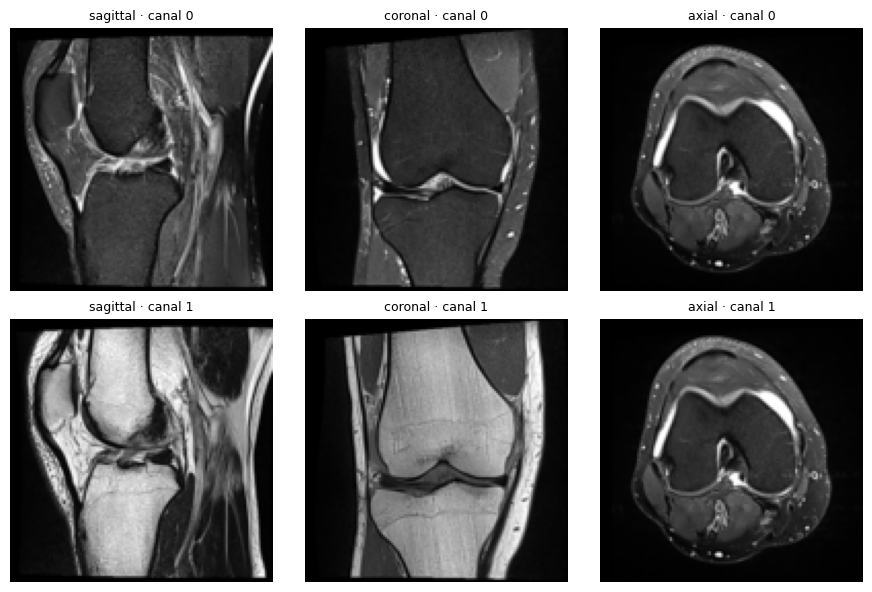

In [8]:
if MODE == "train":
    ids = [s for s in study_ids if W[POS[s]].sum() > 0]
    ids = sorted(ids, key=lambda s: not REAL_MASK[POS[s]].any())[:MAX_STUDIES]   # CAMBIO: los de etiqueta dorada primero (no se pierden con MAX_STUDIES)
    t0 = time.time()
    FPS = build_cache(ids, stbl, TRAIN_DIR, CACHE / "train", n_jobs=N_JOBS)
    print(f"{len(FPS)} estudios en caché ({time.time()-t0:.0f}s)")
    idx = np.array([POS[s] for s in ids if s in FPS])
    tr_ids = [study_ids[i] for i in idx]
    groups = pd.factorize(pd.Series([FPS[s] for s in tr_ids]))[0]
    print("huellas de escáner distintas:", groups.max() + 1)
    FOLDS = list(GroupKFold(N_FOLDS).split(idx, groups=groups))     # misma partición para TODAS las configuraciones
    print("estudios con etiqueta dorada por fold de validación:",
          [int(REAL_MASK[idx[va]].any(1).sum()) for _, va in FOLDS], "| total:", int(REAL_MASK[idx].any(1).sum()))

    # vistazo: corte central de cada plano/canal de un estudio
    x = np.load(CACHE / "train" / f"{tr_ids[0]}.npy")
    fig, ax = plt.subplots(2, 3, figsize=(9, 6))
    for p in range(3):
        for c in range(2):
            ax[c, p].imshow(x[p, N_SLICES // 2, c], cmap="gray"); ax[c, p].axis("off")
            ax[c, p].set_title(f"{PLANES[p]} · canal {c}", fontsize=9)
    plt.tight_layout(); plt.show()

## Desbalance de clases
Se cuantifica la prevalencia de cada hallazgo **en la muestra efectivamente usada** (los estudios en caché). Se separan:
- **gold**: etiqueta dorada (con IC de Wilson al 95 %; con n≈58 son anchos);
- **derivadas**: etiqueta extraída del reporte por reglas.

muestra: 3127 estudios | con etiqueta dorada en ≥1 hallazgo: 58


,label,n_etiquetados,cobertura,n_pos,prev_etiquetados,prev_cota_inf,n_gold,pos_gold,prev_gold,gold_IC95,n_derivadas,pos_derivadas,prev_derivadas
1,MCL,1348,0.431,279,0.207,0.089,58,9,0.155,"[0.08, 0.27]",1290,270,0.209
0,ACL,1514,0.484,517,0.341,0.165,58,24,0.414,"[0.30, 0.54]",1456,493,0.339
3,Lateral Meniscus,1648,0.527,611,0.371,0.195,58,23,0.397,"[0.28, 0.53]",1590,588,0.370
11,Fracture,973,0.311,538,0.553,0.172,58,18,0.310,"[0.21, 0.44]",915,520,0.568
10,Contusion,1110,0.355,644,0.580,0.206,58,19,0.328,"[0.22, 0.46]",1052,625,0.594
9,Baker's,1614,0.516,1055,0.654,0.337,58,12,0.207,"[0.12, 0.33]",1556,1043,0.670
7,Effusion,2353,0.752,1567,0.666,0.501,58,35,0.603,"[0.47, 0.72]",2295,1532,0.668
2,Medial Meniscus,1403,0.449,940,0.670,0.301,58,26,0.448,"[0.33, 0.58]",1345,914,0.680
6,PF OA,1375,0.440,969,0.705,0.310,58,21,0.362,"[0.25, 0.49]",1317,948,0.720
5,Lateral OA,779,0.249,651,0.836,0.208,58,11,0.190,"[0.11, 0.31]",721,640,0.888


hallazgos RAROS (prev < 10% o los 3 menos prevalentes): ['MCL', 'ACL', 'Lateral Meniscus']
con < 5 positivos dorados (AUC gold poco fiable o indefinido): []


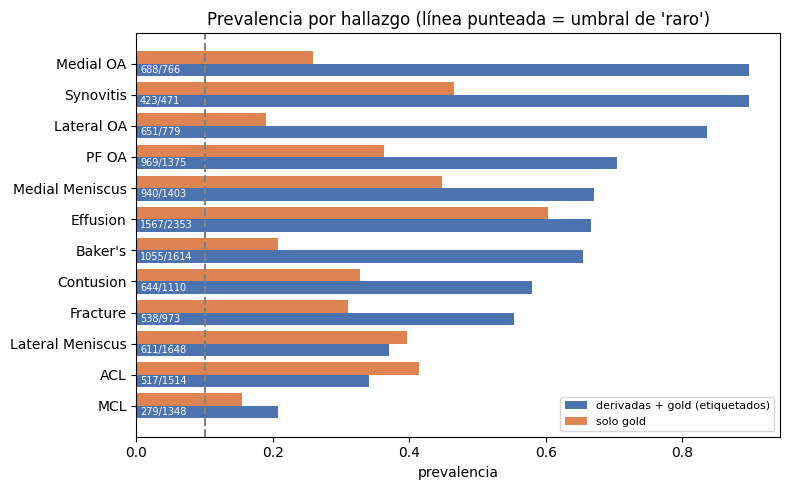

In [9]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def prevalence_table(rows_idx):
    Yi, Wi, Ri = Y[rows_idx], W[rows_idx], REAL_MASK[rows_idx]
    out = []
    for j, l in enumerate(LABELS):
        lab, gold = Wi[:, j] > 0, Ri[:, j]
        wk = lab & ~gold
        k, n = int(Yi[lab, j].sum()), int(lab.sum())
        kg, ng = int(Yi[gold, j].sum()), int(gold.sum())
        kw, nw = int(Yi[wk, j].sum()), int(wk.sum())
        lo, hi = wilson(kg, ng)
        out.append(dict(label=l, n_etiquetados=n, cobertura=n / len(rows_idx), n_pos=k,
                        prev_etiquetados=k / n if n else np.nan, prev_cota_inf=k / len(rows_idx),
                        n_gold=ng, pos_gold=kg, prev_gold=kg / ng if ng else np.nan, gold_IC95=f"[{lo:.2f}, {hi:.2f}]",
                        n_derivadas=nw, pos_derivadas=kw, prev_derivadas=kw / nw if nw else np.nan))
    return pd.DataFrame(out)

RARE_LABELS = []
if MODE == "train":
    PREV = prevalence_table(idx)
    RARE_LABELS = PREV.loc[PREV.prev_etiquetados < RARE_PREV, "label"].tolist()
    if len(RARE_LABELS) < 2:       # si casi nada es < RARE_PREV, se toman los 3 menos prevalentes
        RARE_LABELS = PREV.nsmallest(3, "prev_etiquetados")["label"].tolist()
    print(f"muestra: {len(idx)} estudios | con etiqueta dorada en ≥1 hallazgo: {int(REAL_MASK[idx].any(1).sum())}")
    display(PREV.sort_values("prev_etiquetados").round(3))
    print("hallazgos RAROS (prev < %.0f%% o los 3 menos prevalentes):" % (100 * RARE_PREV), RARE_LABELS)
    sparse_gold = PREV.loc[PREV.pos_gold < MIN_POS_THR, "label"].tolist()
    print(f"con < {MIN_POS_THR} positivos dorados (AUC gold poco fiable o indefinido):", sparse_gold)

    o = PREV.sort_values("prev_etiquetados")
    fig, ax = plt.subplots(figsize=(8, 5)); y = np.arange(len(o))
    ax.barh(y - 0.2, o.prev_etiquetados.fillna(0), 0.4, label="derivadas + gold (etiquetados)", color="#4C72B0")
    ax.barh(y + 0.2, o.prev_gold.fillna(0), 0.4, label="solo gold", color="#DD8452")
    ax.axvline(RARE_PREV, ls="--", c="gray"); ax.set_yticks(y); ax.set_yticklabels(o.label)
    for yy, (n, k) in enumerate(zip(o.n_etiquetados, o.n_pos)): ax.text(0.005, yy - 0.2, f"{k}/{n}", va="center", fontsize=7, color="white")
    ax.set_xlabel("prevalencia"); ax.set_title("Prevalencia por hallazgo (línea punteada = umbral de 'raro')"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    PREV.to_csv(WORK / "prevalencia.csv", index=False)

## 5. Dataset y modelo — transfer learning con backbone preentrenado en ImageNet

**Arquitectura **

```
x (B, 3 planos, N cortes, 2 canales, H, W)
  └─ cada corte ─► BACKBONE 2D preentrenado en ImageNet (timm, sin capa de clasificación) ─► vector f ∈ R^d
        └─ attention pooling sobre los N cortes ─► 1 vector por plano
              └─ concatenación de planos ─► Dropout ─► Linear(planos·d, 12) ─► 12 logits ─► σ(·) por salida
```

- El backbone se inicializa con los pesos aprendidos en ImageNet (`USE_IMAGENET=True`) en lugar de al azar. La **primera convolución** se adapta de 3 canales (RGB) a 2 (serie fluido-sensible y serie normal): se promedian los filtros RGB, se replican y se reescalan por 3/2, de modo que dos canales idénticos producen la misma respuesta que una imagen gris replicada en RGB.

**12 salidas sigmoides independientes**
- Produce **12 logits**, uno por hallazgo, y cada uno pasa por **su propio sigmoide** (`KneeNet.proba`). No hay *softmax*: los hallazgos **no son excluyentes** (un estudio puede tener LCA roto, derrame y quiste de Baker a la vez) y las probabilidades **no suman 1**.
- La pérdida (BCE o focal) se calcula **por salida** y se enmascara con los pesos `W`: una etiqueta faltante de un estudio no afecta a las demás salidas.

In [10]:
import timm

_RAM = {}   # cada .npy se lee (y se reduce) una sola vez; luego vive en memoria

class KneeDS(Dataset):
    def __init__(self, ids, split, Y=None, W=None, aug=False):
        self.ids, self.split, self.Y, self.W, self.aug = ids, split, Y, W, aug
    def __len__(self): return len(self.ids)

    def _get(self, sid):
        key = (self.split, sid, SLICE_STEP, RES)
        if key not in _RAM:
            x = torch.from_numpy(np.load(CACHE / self.split / f"{sid}.npy"))[:, ::SLICE_STEP]   # (3,n,2,H,W) uint8
            if RES != x.shape[-1]:
                P, N, C, H, W_ = x.shape
                x = F.interpolate(x.reshape(P * N, C, H, W_).float(), size=(RES, RES),
                                  mode="bilinear", antialias=True, align_corners=False)
                x = x.round().clamp(0, 255).to(torch.uint8).reshape(P, N, C, RES, RES)
            _RAM[key] = x.contiguous()
        return _RAM[key]

    def __getitem__(self, i):
        x = self._get(self.ids[i])                                   # uint8, sin normalizar
        present = (x.reshape(3, -1).amax(1) > 0).float()
        if self.aug:
            x = torch.roll(x, (random.randint(-6, 6), random.randint(-6, 6)), (-2, -1))
        y = torch.from_numpy(self.Y[i]) if self.Y is not None else torch.zeros(len(LABELS))
        w = torch.from_numpy(self.W[i]) if self.W is not None else torch.zeros(len(LABELS))
        return x, present, y, w

# Estadísticos de ImageNet. La RM es de 1 canal de intensidad: se usa el promedio de las medias y desviaciones RGB
# (0.485, 0.456, 0.406 -> 0.449 ; 0.229, 0.224, 0.225 -> 0.226) para que la entrada tenga la escala que vio el backbone.
IMAGENET_MEAN, IMAGENET_STD = 0.449, 0.226

def prep(x, aug=False):
    """Normaliza con estadísticos de ImageNet (y aplica brillo/contraste por plano) en el dispositivo. x: (B,3,n,2,H,W) uint8."""
    x = x.float().div_(255).sub_(IMAGENET_MEAN).div_(IMAGENET_STD)
    if aug:
        a = 1 + 0.15 * torch.randn(x.shape[0], 3, 1, 1, 1, 1, device=x.device)
        b = 0.15 * torch.randn(x.shape[0], 3, 1, 1, 1, 1, device=x.device)
        x = x * a + b
    return x

_TL_LOGGED = set()

def load_imagenet_sd(enc, sd, origin):
    """Carga en `enc` un state_dict ImageNet (3 canales). Adapta la 1ª convolución a C canales y verifica la carga."""
    msd = enc.state_dict(); sd = dict(sd)
    for k, v in list(sd.items()):
        if k in msd and v.ndim == 4 and v.shape[1] == 3 and msd[k].shape[1] != 3:      # 1ª conv: RGB -> C canales
            C = msd[k].shape[1]
            sd[k] = v.mean(1, keepdim=True).repeat(1, C, 1, 1) * 3 / C                 # misma respuesta ante C canales idénticos
    sd = {k: v for k, v in sd.items() if k in msd and v.shape == msd[k].shape}         # descarta el clasificador de 1000 clases
    frac = len(sd) / max(len(msd), 1)
    if frac < 0.9:
        raise RuntimeError(f"Los pesos de '{origin}' no corresponden a este backbone: solo coinciden {len(sd)}/{len(msd)} tensores. "
                           "Verifica que BACKBONE sea el mismo con el que se creó el state_dict.")
    enc.load_state_dict(sd, strict=False)
    key = (origin, len(msd))
    if key not in _TL_LOGGED:                                                         # se construye un modelo por fold/config: log una sola vez
        _TL_LOGGED.add(key); print(f"[transfer learning] backbone preentrenado en ImageNet ({origin}): {len(sd)}/{len(msd)} tensores cargados")

def build_backbone(name, in_chans, pretrained):
    """Backbone 2D de timm sin capa de clasificación (num_classes=0 -> vector de num_features por imagen).
    pretrained: True  -> pesos ImageNet de timm (descarga; requiere Internet)
                ruta  -> state_dict ImageNet local (sin Internet)
                False -> inicialización aleatoria (línea base / pesos que luego se cargan de un checkpoint)"""
    sd, origin = None, None
    if pretrained is True:
        try:
            sd, origin = timm.create_model(name, pretrained=True, num_classes=0).state_dict(), f"timm/{name}"
        except Exception as e:      # sin Internet: NO se cae en silencio a pesos aleatorios, eso invalidaría el transfer learning
            raise RuntimeError(f"No se pudieron descargar los pesos ImageNet de '{name}' ({type(e).__name__}). Activa Internet en el notebook, "
                               "o sube un state_dict ImageNet como dataset y apunta PRETRAINED_WEIGHTS; o pon USE_IMAGENET=False.") from e
    elif pretrained:
        sd, origin = torch.load(pretrained, map_location="cpu"), str(pretrained)
    enc = timm.create_model(name, pretrained=False, in_chans=in_chans, num_classes=0)
    if sd is not None: load_imagenet_sd(enc, sd, origin)
    return enc

class KneeNet(nn.Module):
    """Transfer learning multietiqueta: backbone 2D preentrenado en ImageNet (compartido por todos los cortes)
    -> attention pooling sobre cortes -> concatenación de planos -> Dropout -> Linear(., 12) -> 12 logits.
    Cada logit pasa por su PROPIO sigmoide (`proba`): 12 salidas independientes y no excluyentes (sin softmax).
    pretrained: True = pesos ImageNet de timm | ruta = state_dict ImageNet local | False = aleatorio (p. ej. al cargar un checkpoint).
    prior: prevalencias de los 12 hallazgos; inicializa el sesgo de cada salida en logit(prevalencia).
    planes: índices de PLANES a usar (0=sagital, 1=coronal, 2=axial); chans: 0=serie fluido-sensible, 1=serie normal.
    Estos dos argumentos existen para la ablación de secuencia/plano (sección 8); por defecto se usa todo."""
    def __init__(self, backbone=BACKBONE, n_out=len(LABELS), pretrained=False, planes=(0, 1, 2), chans=(0, 1), prior=None, drop=HEAD_DROPOUT):
        super().__init__()
        self.planes, self.chans = tuple(planes), tuple(chans)
        self.enc = build_backbone(backbone, len(self.chans), pretrained)
        d = self.enc.num_features
        self.att = nn.Sequential(nn.Linear(d, 128), nn.Tanh(), nn.Linear(128, 1))
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(len(self.planes) * d, n_out))   # 12 logits, uno por hallazgo
        nn.init.normal_(self.head[1].weight, std=0.01)
        if prior is None: nn.init.zeros_(self.head[1].bias)
        else:                                                                                 # σ(sesgo) = prevalencia al iniciar
            p = np.clip(np.asarray(prior, np.float32), 1e-3, 1 - 1e-3)
            with torch.no_grad(): self.head[1].bias.copy_(torch.from_numpy(np.log(p / (1 - p))))
    def forward(self, x, present, return_att=False):     # x: (B,3,n,2,H,W)
        x = x[:, list(self.planes)][:, :, :, list(self.chans)]
        present = present[:, list(self.planes)]
        B, P, N, C, H, W_ = x.shape
        f = self.enc(x.reshape(B * P * N, C, H, W_).contiguous(memory_format=torch.channels_last)).view(B, P, N, -1)
        a = self.att(f).softmax(2)                       # atención sobre cortes (B,P,N,1)
        pooled = (a * f).sum(2) * present.unsqueeze(-1)  # planos ausentes -> 0
        out = self.head(pooled.flatten(1))               # logits (B,12)
        return (out, a.squeeze(-1)) if return_att else out
    def proba(self, x, present):
        """12 probabilidades independientes: sigmoide por salida (multietiqueta; no suman 1)."""
        return torch.sigmoid(self(x, present).float())

def init_weights():
    """Valor de `pretrained` para KneeNet según la configuración global (USE_IMAGENET / PRETRAINED_WEIGHTS)."""
    return (PRETRAINED_WEIGHTS or True) if USE_IMAGENET else False

def macro_auc(Y, P, M):
    aucs = []
    for j in range(Y.shape[1]):
        m = M[:, j] > 0
        aucs.append(roc_auc_score(Y[m, j], P[m, j]) if m.sum() > 0 and len(np.unique(Y[m, j])) == 2 else np.nan)
    return (float(np.nanmean(aucs)) if not np.all(np.isnan(aucs)) else float("nan")), aucs

@torch.no_grad()
def predict(models, ids, split, bs=8):
    dl = DataLoader(KneeDS(ids, split), batch_size=bs, shuffle=False, num_workers=0)
    out = []
    for x, pr, _, _ in dl:
        x, pr = prep(x.to(DEVICE)), pr.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            p = torch.stack([m.proba(x, pr) for m in models]).mean(0)       # sigmoide por salida; ensamble = promedio de modelos
        out.append(p.cpu().numpy())
    return np.concatenate(out)


## 6. Entrenamiento configurable (GroupKFold por huella de escáner)


In [11]:
import hashlib
from torch.utils.data import WeightedRandomSampler
LN = len(LABELS)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# Firma de la arquitectura/optimización: entra en el hash de run_config para NO reutilizar OOF de otra configuración de modelo
ARCH_SIG = dict(backbone=BACKBONE, init="imagenet" if USE_IMAGENET else "scratch", norm="imagenet", lr=LR,
                bb_lr_mult=BB_LR_MULT, freeze=FREEZE_EPOCHS, drop=HEAD_DROPOUT)

def set_backbone_trainable(model, flag):
    for p in model.enc.parameters(): p.requires_grad_(flag)

BASE = dict(name="base", planes=(0, 1, 2), chans=(0, 1), loss="bce", noise="uniform", pos_weight=False, oversample=False)
def make_cfg(name, **kw):
    c = dict(BASE); c.update(kw); c["name"] = name; return c

# ---------- pérdidas ----------
def focal_bce(logit, y, gamma):
    """BCE * (1 - p_t)^gamma. Sin factor alpha: con positivos raros, alpha<0.5 (habitual) restaría peso justo a lo que se quiere aprender."""
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    return bce * (1 - torch.exp(-bce)) ** gamma          # exp(-bce) = p_t

# ---------- pesos por etiqueta según la estrategia de ruido ----------
def label_reliability(rows):
    """Acuerdo regla-vs-gold por etiqueta, calculado SOLO con las filas de entrenamiento `rows`."""
    r = np.full(LN, np.nan)
    for j in range(LN):
        m = ~np.isnan(REAL[rows, j]) & ~np.isnan(WEAK[rows, j])
        if m.sum() >= 3: r[j] = float((REAL[rows, j][m] == WEAK[rows, j][m]).mean())
    fill = np.nanmean(r) if not np.all(np.isnan(r)) else 0.7
    return np.where(np.isnan(r), fill, r)

def make_weights(noise, rows):
    gold = ~np.isnan(REAL[rows]); weak_m = np.isnan(REAL[rows]) & ~np.isnan(WEAK[rows])
    Wc = np.zeros((len(rows), LN), np.float32); Wc[gold] = 1.0
    if noise == "gold_only": return Wc
    cf = np.nan_to_num(CONF[rows]) * label_reliability(rows)[None, :]
    if noise == "uniform":
        Wc[weak_m] = WEAK_W
    elif noise == "conf":                     # reparte la MISMA masa total que "uniform", según la confianza
        Wc[weak_m] = cf[weak_m]
        if weak_m.any(): Wc[weak_m] *= WEAK_W / max(float(Wc[weak_m].mean()), 1e-6)
    elif noise == "high_conf":
        Wc[weak_m & (cf >= HC_THR)] = WEAK_W
    else:
        raise ValueError(noise)
    return Wc

# ---------- mitigación del desbalance ----------
def pos_weights(Ytr, Wtr):
    pos, neg = (Ytr * Wtr).sum(0), ((1 - Ytr) * Wtr).sum(0)
    return torch.tensor(np.clip(neg / np.maximum(pos, 1e-6), 1.0, POSW_MAX), dtype=torch.float32)

def make_sampler(Ytr, Wtr):
    prev = (Ytr * Wtr).sum(0) / np.maximum(Wtr.sum(0), 1e-6)
    rare = (prev < RARE_PREV) & (Wtr.sum(0) > 0)                 # "raro" según el fold de ENTRENAMIENTO
    has = ((Ytr > 0) & (Wtr > 0) & rare[None, :]).any(1)
    sw = 1.0 + OVERSAMPLE * has
    return WeightedRandomSampler(torch.tensor(sw, dtype=torch.double), num_samples=len(sw), replacement=True)

# ---------- entrenamiento de un fold ----------
def train_fold(k, cfg, save_path=None, verbose=True):
    tr_i, va_i = FOLDS[k]
    rows_tr = idx[tr_i]
    Wc, Ytr = make_weights(cfg["noise"], rows_tr), Y[rows_tr]
    keep = Wc.sum(1) > 0                                         # estudios sin ninguna etiqueta útil no aportan
    sel = tr_i[keep]
    Yk, Wk = Ytr[keep], Wc[keep]
    sampler = make_sampler(Yk, Wk) if cfg["oversample"] else None
    dl = DataLoader(KneeDS([tr_ids[i] for i in sel], "train", Yk, Wk, aug=True), batch_size=BS,
                    shuffle=sampler is None, sampler=sampler, num_workers=0, drop_last=True, pin_memory=(DEVICE == "cuda"))
    assert len(dl) > 0, f"config {cfg['name']}: muy pocos estudios de entrenamiento ({len(sel)}) para BS={BS}"
    pw = pos_weights(Yk, Wk).to(DEVICE) if cfg["pos_weight"] else None
    seed_all(SEED + k)                                           # misma inicialización para todas las configs
    model = KneeNet(backbone=BACKBONE, pretrained=init_weights(), planes=cfg["planes"], chans=cfg["chans"], prior=PRIOR).to(DEVICE)
    # tasas de aprendizaje discriminativas: backbone preentrenado (ajuste fino, más lento) vs. atención + cabeza (nuevas, al azar)
    lr_bb = LR * BB_LR_MULT if USE_IMAGENET else LR
    head_params = list(model.att.parameters()) + list(model.head.parameters())
    opt = torch.optim.AdamW([{"params": list(model.enc.parameters()), "lr": lr_bb}, {"params": head_params, "lr": LR}], weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr_bb, LR], total_steps=EPOCHS * len(dl))
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    warm = FREEZE_EPOCHS if USE_IMAGENET else 0                  # fase 1: backbone congelado (solo cabeza); fase 2: ajuste fino de todo
    assert warm < EPOCHS, "FREEZE_EPOCHS debe ser menor que EPOCHS"
    for ep in range(EPOCHS):
        set_backbone_trainable(model, ep >= warm)
        model.train(); t0, tot = time.time(), 0.0
        for x, pr, y, w in dl:
            x, pr, y, w = prep(x.to(DEVICE), aug=True), pr.to(DEVICE), y.to(DEVICE), w.to(DEVICE)
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                logit = model(x, pr)
            logit = logit.float()
            el = focal_bce(logit, y, FOCAL_GAMMA) if cfg["loss"] == "focal" else F.binary_cross_entropy_with_logits(logit, y, reduction="none")
            if pw is not None: el = el * (1 + (pw - 1) * y)      # pos_weight: solo los positivos
            loss = (el * w).sum() / w.sum().clamp(min=1)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        if verbose: print(f"  [{cfg['name']}] fold {k} ep {ep+1}/{EPOCHS} [{'cabeza' if ep < warm else 'ajuste fino'}] loss={tot/len(dl):.4f} ({time.time()-t0:.0f}s)")
    model.eval()
    P = predict([model], [tr_ids[i] for i in va_i], "train")
    if save_path:
        torch.save({"state": model.state_dict(),
                    "cfg": dict(backbone=BACKBONE, img=IMG, n_slices=N_SLICES, res=RES, slice_step=SLICE_STEP,
                                planes=list(cfg["planes"]), chans=list(cfg["chans"]),
                                pretrained="imagenet" if USE_IMAGENET else "scratch", norm="imagenet"),
                    "labels": LABELS, "prior": PRIOR}, save_path)
    del model, opt
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return P, va_i

OOF_DIR = WORK / "oof"; OOF_DIR.mkdir(parents=True, exist_ok=True)
OOF = {}     # nombre de config -> predicciones OOF (n_idx, 12); NaN en los estudios de folds no corridos

def run_config(cfg, folds, save=False):
    h = hashlib.md5(json.dumps({**cfg, "_arch": ARCH_SIG}, sort_keys=True, default=list).encode()).hexdigest()[:6]
    tag = f"{cfg['name'].replace('/', '_').replace('=', '-')}_{h}_f{''.join(map(str, folds))}_e{EPOCHS}_r{RES}_s{SLICE_STEP}"
    f = OOF_DIR / f"{tag}.npy"
    if f.exists() and (not save or all((WORK / f"knee_fold{k}.pt").exists() for k in folds)):
        print(f"[{cfg['name']}] reutilizo {f.name}"); return np.load(f)
    P = np.full((len(idx), LN), np.nan, np.float32)
    for k in folds:
        t0 = time.time()
        Pk, va_i = train_fold(k, cfg, save_path=(WORK / f"knee_fold{k}.pt") if save else None)
        P[va_i] = Pk
        print(f"[{cfg['name']}] fold {k} listo ({time.time()-t0:.0f}s)")
    np.save(f, P); return P

if MODE == "train":
    OOF["base"] = run_config(BASE, RUN_FOLDS, save=True)     # config base: BCE, 3 planos, 2 canales, peso uniforme
    print("OOF base:", int((~np.isnan(OOF["base"]).any(1)).sum()), "estudios con predicción fuera de fold")

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

[transfer learning] backbone preentrenado en ImageNet (timm/resnet18): 120/120 tensores cargados
  [base] fold 0 ep 1/8 [cabeza] loss=0.6030 (37s)
  [base] fold 0 ep 2/8 [ajuste fino] loss=0.5843 (46s)
  [base] fold 0 ep 3/8 [ajuste fino] loss=0.5309 (47s)
  [base] fold 0 ep 4/8 [ajuste fino] loss=0.4940 (49s)
  [base] fold 0 ep 5/8 [ajuste fino] loss=0.4670 (48s)
  [base] fold 0 ep 6/8 [ajuste fino] loss=0.4430 (48s)
  [base] fold 0 ep 7/8 [ajuste fino] loss=0.4226 (48s)
  [base] fold 0 ep 8/8 [ajuste fino] loss=0.4174 (48s)
[base] fold 0 listo (384s)


  [base] fold 1 ep 1/8 [cabeza] loss=0.6094 (18s)
  [base] fold 1 ep 2/8 [ajuste fino] loss=0.5799 (46s)
  [base] fold 1 ep 3/8 [ajuste fino] loss=0.5279 (46s)
  [base] fold 1 ep 4/8 [ajuste fino] loss=0.4983 (46s)
  [base] fold 1 ep 5/8 [ajuste fino] loss=0.4702 (46s)
  [base] fold 1 ep 6/8 [ajuste fino] loss=0.4481 (46s)
  [base] fold 1 ep 7/8 [ajuste fino] loss=0.4306 (46s)
  [base] fold 1 ep 8/8 [ajuste fino] loss=0.4247 (46s)
[base] fold 1 listo (345s)
  [base] fold 2 ep 1/8 [cabeza] loss=0.6039 (18s)
  [base] fold 2 ep 2/8 [ajuste fino] loss=0.5818 (46s)
  [base] fold 2 ep 3/8 [ajuste fino] loss=0.5276 (46s)
  [base] fold 2 ep 4/8 [ajuste fino] loss=0.4881 (46s)
  [base] fold 2 ep 5/8 [ajuste fino] loss=0.4665 (46s)
  [base] fold 2 ep 6/8 [ajuste fino] loss=0.4439 (46s)
  [base] fold 2 ep 7/8 [ajuste fino] loss=0.4236 (46s)
  [base] fold 2 ep 8/8 [ajuste fino] loss=0.4152 (46s)
[base] fold 2 listo (346s)
  [base] fold 3 ep 1/8 [cabeza] loss=0.6063 (18s)
  [base] fold 3 ep 2/8 [aj

## 7. Evaluación con la métrica oficial sobre el conjunto de etiqueta dorada


estudios OOF: 3127 | con etiqueta dorada: 58

>>> AUC macro OFICIAL (gold, OOF): 0.6390  IC95 bootstrap [0.585, 0.688]  | etiquetas evaluables: 12/12
>>> AUC macro sobre etiquetas derivadas (no oficial, mide también al etiquetador): 0.7869


,label,n_gold,pos_gold,AUC_gold,n_derivadas,pos_derivadas,AUC_derivadas
0,ACL,58,24,0.581,1456,493,0.780
1,MCL,58,9,0.498,1290,270,0.795
2,Medial Meniscus,58,26,0.755,1345,914,0.753
3,Lateral Meniscus,58,23,0.678,1590,588,0.747
4,Medial OA,58,15,0.684,708,673,0.705
5,Lateral OA,58,11,0.597,721,640,0.704
6,PF OA,58,21,0.505,1317,948,0.827
7,Effusion,58,35,0.827,2295,1532,0.832
8,Synovitis,58,27,0.670,413,396,0.922
9,Baker's,58,12,0.697,1556,1043,0.850


,label,n_gold,pos_gold,umbral,precisión,recall,F1,umbral@0.5,precisión@0.5,recall@0.5,F1@0.5,origen_umbral
0,ACL,58,24,0.279,0.426,0.833,0.563,0.5,0.533,0.667,0.593,F1-máx (derivadas)
1,MCL,58,9,0.190,0.179,0.778,0.292,0.5,0.214,0.333,0.261,F1-máx (derivadas)
2,Medial Meniscus,58,26,0.364,0.448,1.000,0.619,0.5,0.500,0.962,0.658,F1-máx (derivadas)
3,Lateral Meniscus,58,23,0.289,0.458,0.957,0.620,0.5,0.469,0.652,0.545,F1-máx (derivadas)
4,Medial OA,58,15,0.360,0.259,1.000,0.411,0.5,0.259,1.000,0.411,F1-máx (derivadas)
5,Lateral OA,58,11,0.379,0.190,1.000,0.319,0.5,0.196,1.000,0.328,F1-máx (derivadas)
6,PF OA,58,21,0.355,0.396,1.000,0.568,0.5,0.396,0.905,0.551,F1-máx (derivadas)
7,Effusion,58,35,0.323,0.607,0.971,0.747,0.5,0.642,0.971,0.773,F1-máx (derivadas)
8,Synovitis,58,27,0.276,0.466,1.000,0.635,0.5,0.491,1.000,0.659,F1-máx (derivadas)
9,Baker's,58,12,0.314,0.222,1.000,0.364,0.5,0.213,0.833,0.339,F1-máx (derivadas)


Promedio macro sobre 12 etiquetas con ≥1 positivo dorado | umbral elegido: P=0.361 R=0.953 F1=0.511 | umbral 0.5: P=0.383 R=0.833 F1=0.507


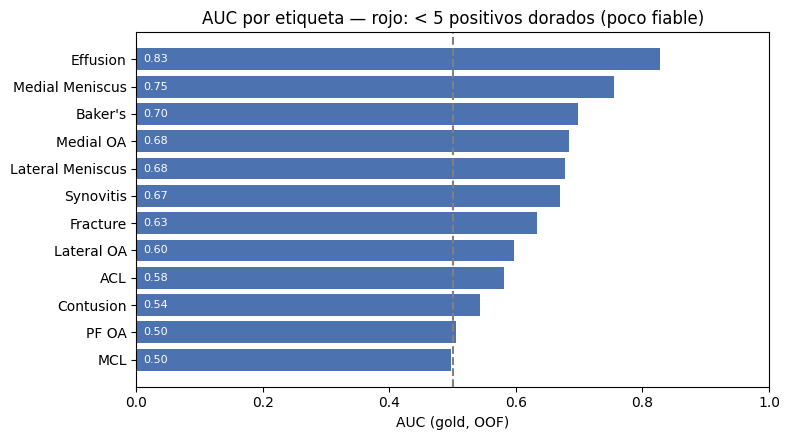

In [12]:
from scipy.stats import rankdata
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score, average_precision_score

def masks(P):
    cov = ~np.isnan(P).any(1)
    Mg = REAL_MASK[idx] & cov[:, None]                          # etiqueta dorada y con predicción OOF
    Mw = (W[idx] > 0) & ~REAL_MASK[idx] & cov[:, None]          # etiqueta derivada del reporte
    return Mg, Mw

def fast_auc(y, p):
    """AUC por rangos (Mann-Whitney); mismo valor que roc_auc_score (empates = 0.5) pero ~20x más rápido."""
    y = np.asarray(y) > 0.5
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0: return np.nan
    return (rankdata(p)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def auc_cols(Yi, P, M, cols=None):
    return {j: fast_auc(Yi[M[:, j], j], P[M[:, j], j]) for j in (range(LN) if cols is None else cols)}

def ap_cols(Yi, P, M, cols=None):
    out = {}
    for j in (range(LN) if cols is None else cols):
        m = M[:, j]
        out[j] = average_precision_score(Yi[m, j], P[m, j]) if m.sum() and Yi[m, j].sum() > 0 else np.nan
    return out

def macro(d):
    v = [x for x in d.values() if not np.isnan(x)]
    return float(np.mean(v)) if v else np.nan

def safe_ci(a):
    a = np.asarray(a, float); a = a[~np.isnan(a)]
    return (np.nan, np.nan) if len(a) < 10 else tuple(np.percentile(a, [2.5, 97.5]))

def boot_macro(Ps, cols=None, B=None, seed=0):
    """Bootstrap PAREADO: todas las configs usan los mismos remuestreos de estudios dorados."""
    B = B or BOOT_B
    cols = list(range(LN)) if cols is None else list(cols)
    cov = np.all([~np.isnan(P).any(1) for P in Ps.values()], axis=0)
    Mg, Yi = REAL_MASK[idx] & cov[:, None], Y[idx]
    gold_rows = np.where(Mg[:, cols].any(1))[0]
    pt = {n: macro(auc_cols(Yi, P, Mg, cols)) for n, P in Ps.items()}
    S = {n: np.full(B, np.nan) for n in Ps}
    if len(gold_rows) == 0: return pt, S
    rng = np.random.default_rng(seed)
    for b in range(B):
        s = rng.choice(gold_rows, len(gold_rows), replace=True)
        for n, P in Ps.items():
            S[n][b] = macro(auc_cols(Yi[s], P[s], Mg[s], cols))
    return pt, S

def per_label_report(P):
    Mg, Mw = masks(P); Yi = Y[idx]
    ag, aw = auc_cols(Yi, P, Mg), auc_cols(Yi, P, Mw)
    return pd.DataFrame([dict(label=l, n_gold=int(Mg[:, j].sum()), pos_gold=int(Yi[Mg[:, j], j].sum()), AUC_gold=ag[j],
                              n_derivadas=int(Mw[:, j].sum()), pos_derivadas=int(Yi[Mw[:, j], j].sum()), AUC_derivadas=aw[j])
                         for j, l in enumerate(LABELS)])

def pick_thresholds(P):
    """Umbral por etiqueta = el que maximiza F1 sobre estudios con etiqueta DERIVADA (disjuntos del conjunto dorado)."""
    _, Mw = masks(P); Yi = Y[idx]; thr, src = np.zeros(LN), []
    for j in range(LN):
        m = Mw[:, j]; y, p = Yi[m, j], P[m, j]
        if m.sum() and y.sum() >= MIN_POS_THR and (1 - y).sum() >= MIN_POS_THR:
            pr, rc, th = precision_recall_curve(y, p)
            f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-9)
            thr[j], s = th[int(np.argmax(f1))], "F1-máx (derivadas)"
        else:
            thr[j], s = PRIOR[j], "prevalencia (fallback)"
        src.append(s)
    return thr, src

def metrics_at(P, thr):
    Mg, _ = masks(P); Yi = Y[idx]; rows = []
    for j, l in enumerate(LABELS):
        m = Mg[:, j]; y = Yi[m, j]
        r = dict(label=l, n_gold=int(m.sum()), pos_gold=int(y.sum()))
        for tag, t in (("", thr[j]), ("@0.5", 0.5)):
            yh = (P[m, j] >= t).astype(int) if m.sum() else np.array([])
            r.update({f"umbral{tag}": t,
                      f"precisión{tag}": precision_score(y, yh, zero_division=0) if y.sum() else np.nan,   # sin positivos dorados no está definida
                      f"recall{tag}": recall_score(y, yh, zero_division=0) if y.sum() else np.nan,
                      f"F1{tag}": f1_score(y, yh, zero_division=0) if y.sum() else np.nan})
        rows.append(r)
    return pd.DataFrame(rows)

if MODE == "train":
    P_base = OOF["base"]
    Mg, _ = masks(P_base)
    print(f"estudios OOF: {int((~np.isnan(P_base).any(1)).sum())} | con etiqueta dorada: {int(Mg.any(1).sum())}")
    pt, S = boot_macro({"base": P_base})
    lo, hi = safe_ci(S["base"])
    tab = per_label_report(P_base)
    n_eval = int(tab.AUC_gold.notna().sum())
    print(f"\n>>> AUC macro OFICIAL (gold, OOF): {pt['base']:.4f}  IC95 bootstrap [{lo:.3f}, {hi:.3f}]  | etiquetas evaluables: {n_eval}/{LN}")
    print(f">>> AUC macro sobre etiquetas derivadas (no oficial, mide también al etiquetador): {macro(dict(enumerate(tab.AUC_derivadas))):.4f}")
    if n_eval < LN: print(f"    AVISO: {LN-n_eval} etiquetas sin positivos o sin negativos dorados -> no entran en el macro:",
                          tab.loc[tab.AUC_gold.isna(), "label"].tolist())
    display(tab.round(3))

    thr, src = pick_thresholds(P_base)
    mt = metrics_at(P_base, thr); mt["origen_umbral"] = src
    display(mt.round(3))
    ev = mt[mt.pos_gold > 0]
    print(f"Promedio macro sobre {len(ev)} etiquetas con ≥1 positivo dorado | "
          f"umbral elegido: P={ev['precisión'].mean():.3f} R={ev['recall'].mean():.3f} F1={ev['F1'].mean():.3f} | "
          f"umbral 0.5: P={ev['precisión@0.5'].mean():.3f} R={ev['recall@0.5'].mean():.3f} F1={ev['F1@0.5'].mean():.3f}")
    tab.merge(mt.drop(columns=["n_gold", "pos_gold"]), on="label").to_csv(WORK / "eval_gold_por_etiqueta.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 4.5)); t = tab.sort_values("AUC_gold")
    ax.barh(t.label, t.AUC_gold.fillna(0), color=["#C44E52" if p < MIN_POS_THR else "#4C72B0" for p in t.pos_gold])
    for y_, (a, p) in enumerate(zip(t.AUC_gold, t.pos_gold)): ax.text(0.01, y_, "indef." if np.isnan(a) else f"{a:.2f}", va="center", color="white", fontsize=8)
    ax.axvline(0.5, ls="--", c="gray"); ax.set_xlim(0, 1); ax.set_xlabel("AUC (gold, OOF)")
    ax.set_title(f"AUC por etiqueta — rojo: < {MIN_POS_THR} positivos dorados (poco fiable)"); plt.tight_layout(); plt.show()

## 8. Estudio de ablación
Se varían **tres factores**, uno a la vez respecto a la config base (`base`: 3 planos, 2 canales, BCE, peso uniforme `WEAK_W`):

| Factor | Variantes |
|---|---|
| **Secuencia / plano** | solo sagital · solo coronal · solo axial · solo serie fluido-sensible · solo serie normal |
| **Función de pérdida** | BCE (base) vs. **focal** (γ=`FOCAL_GAMMA`) |
| **Etiquetas ruidosas** | `uniform` (base) · `conf` (peso ∝ confianza, misma masa total) · `high_conf` (solo confianza ≥ `HC_THR`) · `gold_only` (referencia: ignora las derivadas) |

[base] reutilizo base_c932ac_f01234_e8_r128_s1.npy
  [plano=sagital] fold 0 ep 1/8 [cabeza] loss=0.6038 (8s)
  [plano=sagital] fold 0 ep 2/8 [ajuste fino] loss=0.6000 (22s)
  [plano=sagital] fold 0 ep 3/8 [ajuste fino] loss=0.5720 (18s)
  [plano=sagital] fold 0 ep 4/8 [ajuste fino] loss=0.5362 (18s)
  [plano=sagital] fold 0 ep 5/8 [ajuste fino] loss=0.5115 (18s)
  [plano=sagital] fold 0 ep 6/8 [ajuste fino] loss=0.4939 (18s)
  [plano=sagital] fold 0 ep 7/8 [ajuste fino] loss=0.4846 (18s)
  [plano=sagital] fold 0 ep 8/8 [ajuste fino] loss=0.4702 (18s)
[plano=sagital] fold 0 listo (140s)
  [plano=sagital] fold 1 ep 1/8 [cabeza] loss=0.6094 (8s)
  [plano=sagital] fold 1 ep 2/8 [ajuste fino] loss=0.6040 (18s)
  [plano=sagital] fold 1 ep 3/8 [ajuste fino] loss=0.5704 (18s)
  [plano=sagital] fold 1 ep 4/8 [ajuste fino] loss=0.5334 (18s)
  [plano=sagital] fold 1 ep 5/8 [ajuste fino] loss=0.5103 (18s)
  [plano=sagital] fold 1 ep 6/8 [ajuste fino] loss=0.4916 (18s)
  [plano=sagital] fold 1 ep 7

,config,AUC_gold,IC95,delta,IC95_delta,veredicto,AUC_derivadas,AP_derivadas,etiquetas_gold
0,base,0.639,"[0.585, 0.688]",0.000,"[+0.000, +0.000]",—,0.787,0.819,12/12
1,plano=sagital,0.621,"[0.575, 0.670]",-0.018,"[-0.079, +0.040]",no concluyente,0.738,0.780,12/12
2,plano=coronal,0.601,"[0.553, 0.644]",-0.038,"[-0.076, +0.001]",no concluyente,0.745,0.794,12/12
3,plano=axial,0.588,"[0.539, 0.642]",-0.051,"[-0.092, -0.009]",empeora,0.740,0.790,12/12
4,canal=fluido,0.603,"[0.540, 0.659]",-0.036,"[-0.084, +0.008]",no concluyente,0.784,0.813,12/12
5,canal=normal,0.621,"[0.565, 0.672]",-0.018,"[-0.061, +0.022]",no concluyente,0.791,0.822,12/12


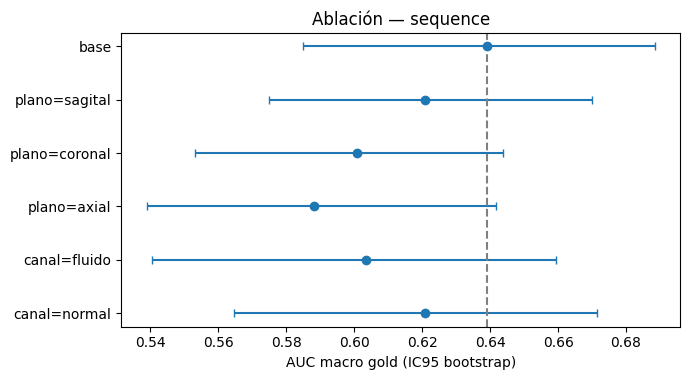


=== Ablación: loss ===


,config,AUC_gold,IC95,delta,IC95_delta,veredicto,AUC_derivadas,AP_derivadas,etiquetas_gold
0,base,0.639,"[0.585, 0.688]",0.000,"[+0.000, +0.000]",—,0.787,0.819,12/12
1,loss=focal,0.635,"[0.577, 0.687]",-0.004,"[-0.034, +0.022]",no concluyente,0.789,0.824,12/12


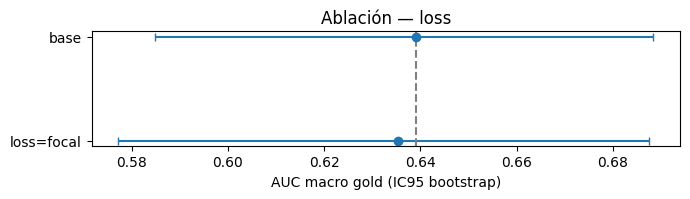


=== Ablación: noise ===


,config,AUC_gold,IC95,delta,IC95_delta,veredicto,AUC_derivadas,AP_derivadas,etiquetas_gold
0,base,0.639,"[0.585, 0.688]",0.000,"[+0.000, +0.000]",—,0.787,0.819,12/12
1,ruido=conf,0.629,"[0.571, 0.680]",-0.010,"[-0.033, +0.010]",no concluyente,0.791,0.824,12/12
2,ruido=high_conf,0.483,"[0.424, 0.538]",-0.156,"[-0.205, -0.108]",empeora,0.632,0.738,12/12
3,ruido=gold_only,0.357,"[0.307, 0.405]",-0.282,"[-0.341, -0.230]",empeora,0.538,0.664,12/12


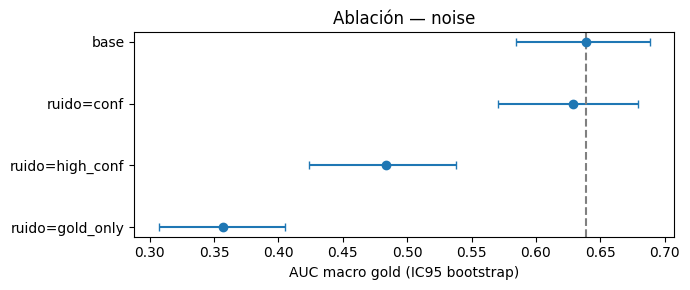


AUC gold por etiqueta y configuración (NaN = indefinido):


,base,plano=sagital,plano=coronal,plano=axial,canal=fluido,canal=normal,loss=focal,ruido=conf,ruido=high_conf,ruido=gold_only
ACL,0.581,0.615,0.570,0.533,0.615,0.577,0.587,0.621,0.603,0.357
MCL,0.498,0.442,0.617,0.442,0.465,0.517,0.529,0.492,0.420,0.374
Medial Meniscus,0.755,0.539,0.588,0.703,0.653,0.733,0.674,0.757,0.608,0.413
Lateral Meniscus,0.678,0.661,0.658,0.763,0.638,0.745,0.687,0.672,0.672,0.338
Medial OA,0.684,0.555,0.603,0.521,0.659,0.650,0.685,0.695,0.501,0.346
Lateral OA,0.597,0.706,0.682,0.447,0.499,0.482,0.565,0.561,0.269,0.331
PF OA,0.505,0.597,0.430,0.502,0.438,0.477,0.515,0.489,0.436,0.329
Effusion,0.827,0.814,0.658,0.817,0.920,0.801,0.834,0.855,0.646,0.380
Synovitis,0.670,0.655,0.594,0.625,0.611,0.620,0.642,0.608,0.549,0.318
Baker's,0.697,0.708,0.562,0.670,0.707,0.727,0.741,0.710,0.221,0.285


In [13]:
CFG = {c["name"]: c for c in [BASE]}
GROUPS = {
    "sequence": [make_cfg("plano=sagital", planes=(0,)), make_cfg("plano=coronal", planes=(1,)), make_cfg("plano=axial", planes=(2,)),
                 make_cfg("canal=fluido", chans=(0,)), make_cfg("canal=normal", chans=(1,))],
    "loss":     [make_cfg("loss=focal", loss="focal")],
    "noise":    [make_cfg("ruido=conf", noise="conf"), make_cfg("ruido=high_conf", noise="high_conf"), make_cfg("ruido=gold_only", noise="gold_only")],
}
for g in GROUPS.values():
    for c in g: CFG[c["name"]] = c

def compare_table(names, ref="base", cols=None):
    names = [ref] + [n for n in names if n != ref]
    Ps = {n: OOF[n] for n in names}
    pt, S = boot_macro(Ps, cols)
    Yi, cs, rows = Y[idx], (list(range(LN)) if cols is None else list(cols)), []
    for n, P in Ps.items():
        Mg, Mw = masks(P)
        ag = auc_cols(Yi, P, Mg, cs); aw = auc_cols(Yi, P, Mw, cs)
        lo, hi = safe_ci(S[n]); dlo, dhi = safe_ci(S[n] - S[ref])
        rows.append(dict(config=n, AUC_gold=pt[n], lo=lo, hi=hi, delta=pt[n] - pt[ref], dlo=dlo, dhi=dhi,
                         veredicto="—" if n == ref else ("mejora" if dlo > 0 else "empeora" if dhi < 0 else "no concluyente"),
                         AUC_derivadas=macro(aw), AP_derivadas=macro(ap_cols(Yi, P, Mw, cs)),
                         etiquetas_gold=f"{sum(not np.isnan(v) for v in ag.values())}/{len(cs)}"))
    return pd.DataFrame(rows)

def show_table(df, title):
    d = df.copy(); d["IC95"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(d.lo, d.hi)]
    d["IC95_delta"] = [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(d.dlo, d.dhi)]
    print(title); display(d[["config", "AUC_gold", "IC95", "delta", "IC95_delta", "veredicto", "AUC_derivadas", "AP_derivadas", "etiquetas_gold"]].round(3))

def forest(df, title):
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(df) + 1.2)); y = np.arange(len(df))[::-1]
    ax.errorbar(df.AUC_gold, y, xerr=[df.AUC_gold - df.lo, df.hi - df.AUC_gold], fmt="o", capsize=3)
    ax.set_yticks(y); ax.set_yticklabels(df.config); ax.axvline(df.AUC_gold.iloc[0], ls="--", c="gray")
    ax.set_xlabel("AUC macro gold (IC95 bootstrap)"); ax.set_title(title); plt.tight_layout(); plt.show()

ABL_RESULTS = {}
if MODE == "train":
    OOF["base"] = run_config(BASE, ABL_FOLDS)                    # se reutiliza si ABL_FOLDS == RUN_FOLDS (caché)
    for g in ABL_GROUPS:
        for c in GROUPS[g]: OOF[c["name"]] = run_config(c, ABL_FOLDS)
    for g in ABL_GROUPS:
        df = compare_table([c["name"] for c in GROUPS[g]]); ABL_RESULTS[g] = df
        show_table(df, f"\n=== Ablación: {g} ==="); forest(df, f"Ablación — {g}")
    if ABL_RESULTS:
        pd.concat(ABL_RESULTS.values()).drop_duplicates("config").to_csv(WORK / "ablacion.csv", index=False)
        names = ["base"] + [c["name"] for g in ABL_GROUPS for c in GROUPS[g]]
        piv = pd.DataFrame({n: pd.Series(auc_cols(Y[idx], OOF[n], masks(OOF[n])[0])) for n in names}); piv.index = LABELS
        print("\nAUC gold por etiqueta y configuración (NaN = indefinido):"); display(piv.round(3))

## 9. Mitigación del desbalance en hallazgos raros


In [14]:
MIT_CFGS = {"pos_weight": make_cfg("mit=pos_weight", pos_weight=True),
            "oversample": make_cfg("mit=oversample", oversample=True)}
MIT_RESULTS = None
if MODE == "train":
    for c in MIT_CFGS.values(): OOF[c["name"]] = run_config(c, ABL_FOLDS)
    OOF["loss=focal"] = run_config(CFG["loss=focal"], ABL_FOLDS)
    rare_cols = [LABELS.index(l) for l in RARE_LABELS]
    names = ["base", "mit=pos_weight", "loss=focal", "mit=oversample"]
    print("hallazgos raros evaluados:", RARE_LABELS)
    print("\n--- Macro sobre los hallazgos RAROS ---")
    MIT_RESULTS = compare_table(names, cols=rare_cols); show_table(MIT_RESULTS, "")
    print("--- Macro sobre las 12 etiquetas (¿se degrada lo frecuente?) ---")
    show_table(compare_table(names), "")
    rows = []
    for n in names:
        Mg, Mw = masks(OOF[n]); Yi = Y[idx]
        a, p = auc_cols(Yi, OOF[n], Mw, rare_cols), ap_cols(Yi, OOF[n], Mw, rare_cols)
        g = auc_cols(Yi, OOF[n], Mg, rare_cols)
        for j in rare_cols: rows.append(dict(config=n, label=LABELS[j], AUC_gold=g[j], pos_gold=int(Yi[Mg[:, j], j].sum()), AUC_derivadas=a[j], AP_derivadas=p[j]))
    det = pd.DataFrame(rows)
    print("\nDetalle por hallazgo raro (AP de referencia = prevalencia; AUC_gold NaN si no hay positivos dorados):")
    display(det.pivot(index="label", columns="config", values=["AUC_derivadas", "AP_derivadas"]).round(3))
    display(det.pivot(index="label", columns="config", values="AUC_gold").round(3))
    MIT_RESULTS.to_csv(WORK / "mitigacion_raros.csv", index=False)

  [mit=pos_weight] fold 0 ep 1/8 [cabeza] loss=0.7405 (18s)
  [mit=pos_weight] fold 0 ep 2/8 [ajuste fino] loss=0.7001 (47s)
  [mit=pos_weight] fold 0 ep 3/8 [ajuste fino] loss=0.6443 (46s)
  [mit=pos_weight] fold 0 ep 4/8 [ajuste fino] loss=0.5972 (46s)
  [mit=pos_weight] fold 0 ep 5/8 [ajuste fino] loss=0.5662 (46s)
  [mit=pos_weight] fold 0 ep 6/8 [ajuste fino] loss=0.5325 (46s)
  [mit=pos_weight] fold 0 ep 7/8 [ajuste fino] loss=0.5090 (46s)
  [mit=pos_weight] fold 0 ep 8/8 [ajuste fino] loss=0.5063 (46s)
[mit=pos_weight] fold 0 listo (346s)
  [mit=pos_weight] fold 1 ep 1/8 [cabeza] loss=0.7321 (18s)
  [mit=pos_weight] fold 1 ep 2/8 [ajuste fino] loss=0.6811 (46s)
  [mit=pos_weight] fold 1 ep 3/8 [ajuste fino] loss=0.6219 (46s)
  [mit=pos_weight] fold 1 ep 4/8 [ajuste fino] loss=0.5813 (46s)
  [mit=pos_weight] fold 1 ep 5/8 [ajuste fino] loss=0.5482 (46s)
  [mit=pos_weight] fold 1 ep 6/8 [ajuste fino] loss=0.5206 (46s)
  [mit=pos_weight] fold 1 ep 7/8 [ajuste fino] loss=0.4974 (46s

,config,AUC_gold,IC95,delta,IC95_delta,veredicto,AUC_derivadas,AP_derivadas,etiquetas_gold
0,base,0.586,"[0.487, 0.684]",0.000,"[+0.000, +0.000]",—,0.774,0.570,3/3
1,mit=pos_weight,0.610,"[0.512, 0.717]",0.024,"[-0.034, +0.089]",no concluyente,0.782,0.582,3/3
2,loss=focal,0.601,"[0.510, 0.704]",0.016,"[-0.034, +0.070]",no concluyente,0.770,0.569,3/3
3,mit=oversample,0.607,"[0.519, 0.707]",0.021,"[-0.041, +0.080]",no concluyente,0.774,0.578,3/3


--- Macro sobre las 12 etiquetas (¿se degrada lo frecuente?) ---



,config,AUC_gold,IC95,delta,IC95_delta,veredicto,AUC_derivadas,AP_derivadas,etiquetas_gold
0,base,0.639,"[0.585, 0.688]",0.000,"[+0.000, +0.000]",—,0.787,0.819,12/12
1,mit=pos_weight,0.622,"[0.566, 0.672]",-0.017,"[-0.049, +0.019]",no concluyente,0.792,0.823,12/12
2,loss=focal,0.635,"[0.577, 0.687]",-0.004,"[-0.034, +0.022]",no concluyente,0.789,0.824,12/12
3,mit=oversample,0.635,"[0.581, 0.685]",-0.004,"[-0.036, +0.025]",no concluyente,0.783,0.821,12/12



Detalle por hallazgo raro (AP de referencia = prevalencia; AUC_gold NaN si no hay positivos dorados):


AUC_derivadas                                           \
config                    base loss=focal mit=oversample mit=pos_weight   
label                                                                     
ACL                      0.780      0.773          0.778          0.791   
Lateral Meniscus         0.747      0.750          0.751          0.753   
MCL                      0.795      0.787          0.793          0.801   

                 AP_derivadas                                           
config                   base loss=focal mit=oversample mit=pos_weight  
label                                                                   
ACL                     0.634      0.629          0.643          0.652  
Lateral Meniscus        0.601      0.603          0.619          0.610  
MCL                     0.475      0.476          0.472          0.483

config,base,loss=focal,mit=oversample,mit=pos_weight
label,,,,
ACL,0.581,0.587,0.630,0.589
Lateral Meniscus,0.678,0.687,0.706,0.686
MCL,0.498,0.529,0.485,0.554


## 10. Interpretabilidad: Grad-CAM

hallazgos para Grad-CAM: ['Medial Meniscus', 'ACL', 'Effusion', "Baker's"]


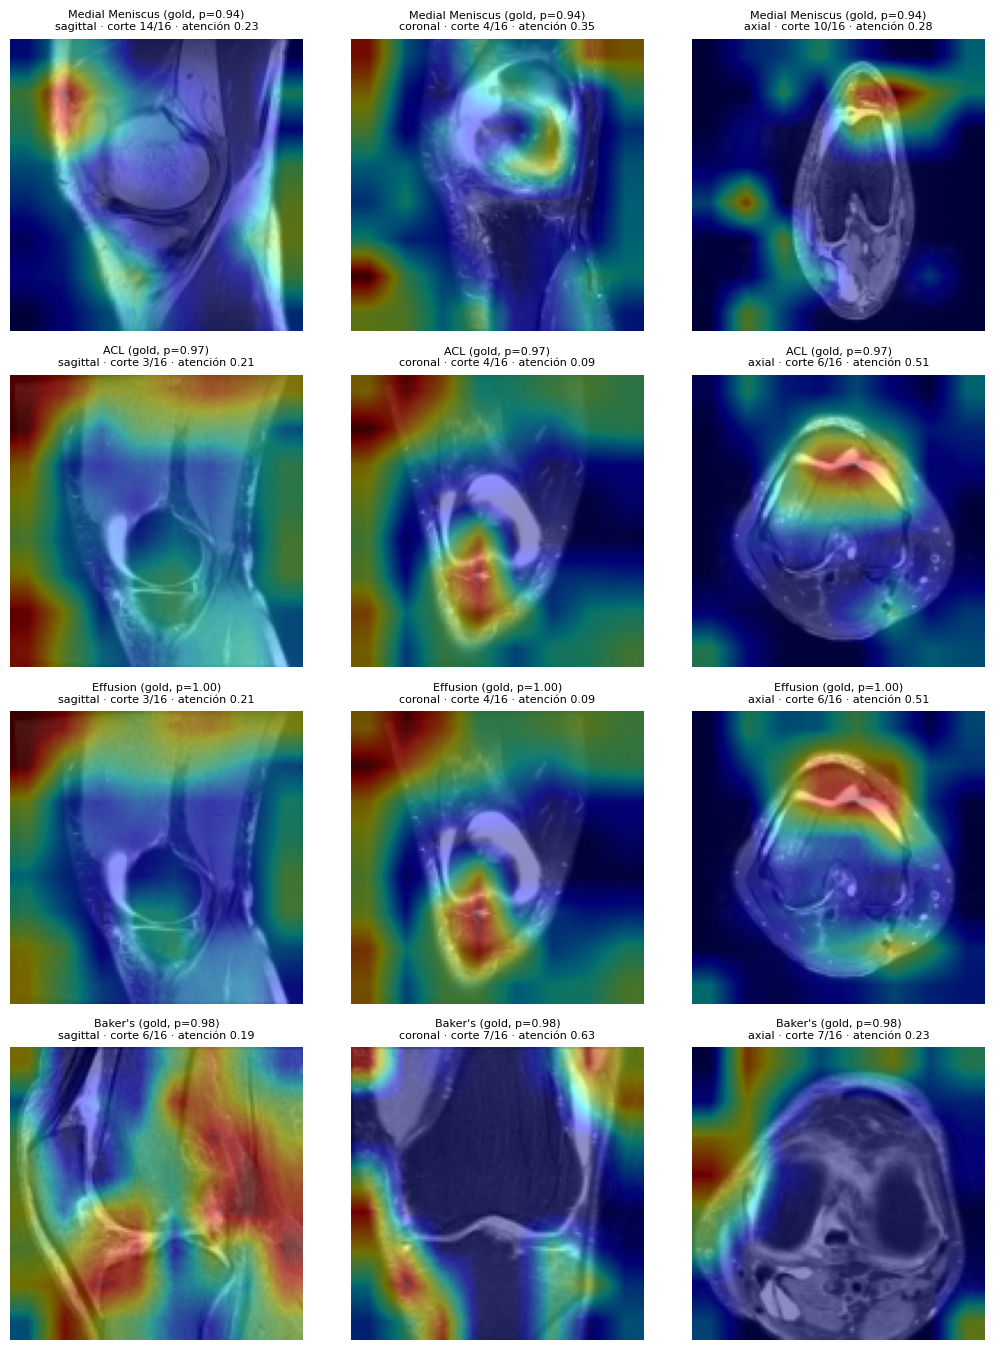


Prueba de cordura (correlación cercana a 1 = el mapa casi no depende de lo aprendido):


,hallazgo,estudio,corr_entrenado_vs_aleatorio
0,Medial Meniscus,1.2.826.0.1.3680043.8.498.73926443729786165628...,0.040
1,ACL,1.2.826.0.1.3680043.8.498.73527530686853911124...,-0.003
2,Effusion,1.2.826.0.1.3680043.8.498.73527530686853911124...,NaN
3,Baker's,1.2.826.0.1.3680043.8.498.12801308844398614687...,-0.024



Prueba de fidelidad (borrado). Fidelidad OK si caída_CAM > caída_azar de forma consistente:


,hallazgo,n_estudios,caida_logit_CAM,caida_logit_azar,pct_casos_CAM_mayor_que_azar
0,Medial Meniscus,10,0.775,1.374,20.0
1,ACL,10,1.882,3.285,0.0
2,Effusion,10,2.710,5.185,0.0
3,Baker's,10,0.895,1.867,30.0


In [15]:
class GradCAM:
    def __init__(self, model, layer):
        mods = dict(model.enc.named_modules())
        if layer not in mods:
            raise ValueError(f"CAM_LAYER='{layer}' no existe en el backbone; opciones: {[n for n, _ in model.enc.named_children()]}")
        self.model, self.acts, self.grads = model, None, None
        self.h = mods[layer].register_forward_hook(self._fwd)
    def _fwd(self, mod, inp, out):
        self.acts = out
        if out.requires_grad: out.register_hook(lambda g: setattr(self, "grads", g))
    def remove(self): self.h.remove()
    def __call__(self, x, pr, j):
        """x: (1,3,n,2,H,H) ya normalizado. Devuelve (cam (P,n,H,H), atención (P,n), probabilidad)."""
        self.model.zero_grad(set_to_none=True); self.grads = None
        out, att = self.model(x, pr, return_att=True)
        out[0, j].backward()
        A, G = self.acts.detach(), self.grads.detach()                         # (P*n, C, h, w)
        cam = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
        H = x.shape[-1]
        cam = F.interpolate(cam, size=(H, H), mode="bilinear", align_corners=False)[:, 0]
        return cam.view(len(self.model.planes), x.shape[2], H, H), att[0].detach(), float(torch.sigmoid(out[0, j]))

def top_mask(score, frac):
    P_, n, H, W_ = score.shape
    flat = score.reshape(P_, n, -1)
    thr = torch.quantile(flat, 1 - frac, dim=-1, keepdim=True)
    return ((flat > thr) & (flat.amax(-1, keepdim=True) > 0)).view(P_, n, H, W_)

def random_mask_like(mask):
    """Máscara aleatoria con el MISMO número de píxeles por corte que `mask`."""
    P_, n, H, W_ = mask.shape
    cnt = mask.reshape(P_, n, -1).sum(-1, keepdim=True)
    rank = torch.rand(P_, n, H * W_, device=mask.device).argsort(-1, descending=True).argsort(-1)
    return (rank < cnt).view(P_, n, H, W_)

@torch.no_grad()
def masked_logit(model, x, pr, j, mask):
    return float(model(x.masked_fill(mask[None, :, :, None], 0.0), pr)[0, j])   # 0 = media tras normalizar

def deletion_test(model, x, pr, j, cam, frac=0.2, n_rand=5):
    none = torch.zeros_like(cam, dtype=torch.bool); base = masked_logit(model, x, pr, j, none)
    m = top_mask(cam, frac)
    d_cam = base - masked_logit(model, x, pr, j, m)
    d_rand = float(np.mean([base - masked_logit(model, x, pr, j, random_mask_like(m)) for _ in range(n_rand)]))
    return d_cam, d_rand

def pick_cases(j, P, n=1):
    cov = ~np.isnan(P).any(1)
    cand = np.where((Y[idx][:, j] == 1) & (W[idx][:, j] > 0) & cov)[0]
    if not len(cand): return []
    order = np.lexsort((-P[cand, j], ~REAL_MASK[idx][cand, j]))      # primero etiqueta dorada, luego mayor probabilidad
    return cand[order][:n].tolist()

def load_fold_model(k):
    ck = torch.load(WORK / f"knee_fold{k}.pt", map_location="cpu")
    m = KneeNet(backbone=ck["cfg"]["backbone"], planes=ck["cfg"].get("planes", (0, 1, 2)), chans=ck["cfg"].get("chans", (0, 1)), pretrained=False)
    m.load_state_dict(ck["state"]); return m.to(DEVICE).eval()          # los pesos (ya ajustados) vienen del checkpoint

def case_tensors(rp):
    sid = tr_ids[rp]; ds = KneeDS([sid], "train")
    x, pr, _, _ = ds[0]
    return sid, ds._get(sid).numpy(), prep(x[None].to(DEVICE)), pr[None].to(DEVICE)

def show_cams(cases, MODELS, fold_of):
    fig, axes = plt.subplots(len(cases), 3, figsize=(10.5, 3.4 * len(cases)), squeeze=False)
    for r, (j, rp) in enumerate(cases):
        sid, raw, x, pr = case_tensors(rp)
        gc = GradCAM(MODELS[fold_of[rp]], CAM_LAYER)
        cam, att, prob = gc(x, pr, j); gc.remove()
        cam, att = cam.cpu().numpy(), att.cpu().numpy()
        src = "gold" if REAL_MASK[idx][rp, j] else "derivada"
        for p in range(3):
            s = int(np.argmax(att[p] * cam[p].reshape(cam.shape[1], -1).sum(1)))
            ax = axes[r, p]; ax.imshow(raw[p, s, 0], cmap="gray")
            ax.imshow(cam[p, s] / (cam[p].max() + 1e-8), cmap="jet", alpha=0.45, vmin=0, vmax=1); ax.axis("off")
            ax.set_title(f"{LABELS[j]} ({src}, p={prob:.2f})\n{PLANES[p]} · corte {s+1}/{cam.shape[1]} · atención {att[p, s]:.2f}", fontsize=8)
    plt.tight_layout(); plt.show()

if MODE == "train":
    P_b = OOF["base"]
    missing = [k for k in RUN_FOLDS if not (WORK / f"knee_fold{k}.pt").exists()]
    assert not missing, f"faltan knee_fold{{k}}.pt para los folds {missing}; corre la sección 6 con save=True"
    fold_of = np.full(len(idx), -1)
    for k, (_, va) in enumerate(FOLDS): fold_of[va] = k
    MODELS = {k: load_fold_model(k) for k in RUN_FOLDS}
    CAM_LABELS = [l for key in CAM_FINDINGS for l in LABELS if norm_name(l) == key]
    if len(CAM_LABELS) < 3:        # completa con las etiquetas de mejor AUC dorado
        extra = per_label_report(P_b).sort_values("AUC_gold", ascending=False).label.tolist()
        CAM_LABELS += [l for l in extra if l not in CAM_LABELS][: 3 - len(CAM_LABELS)]
    print("hallazgos para Grad-CAM:", CAM_LABELS)
    cases = [(LABELS.index(l), rp) for l in CAM_LABELS for rp in pick_cases(LABELS.index(l), P_b, CAM_CASES)]
    if not cases: print("No hay estudios positivos con predicción OOF para los hallazgos pedidos.")
    else:
        show_cams(cases, MODELS, fold_of)

        # --- cordura: ¿el mapa cambia si se aleatorizan los pesos? ---
        seed_all(SEED); rand_model = KneeNet(pretrained=False).to(DEVICE).eval()   # pesos ALEATORIOS (ni ImageNet ni ajustados): línea de referencia de la prueba
        rows = []
        for j, rp in cases:
            sid, raw, x, pr = case_tensors(rp)
            g1 = GradCAM(MODELS[fold_of[rp]], CAM_LAYER); c1, _, _ = g1(x, pr, j); g1.remove()
            g2 = GradCAM(rand_model, CAM_LAYER); c2, _, _ = g2(x, pr, j); g2.remove()
            a, b = c1.flatten().cpu().numpy(), c2.flatten().cpu().numpy()
            rows.append(dict(hallazgo=LABELS[j], estudio=sid, corr_entrenado_vs_aleatorio=float(np.corrcoef(a, b)[0, 1]) if a.std() > 0 and b.std() > 0 else np.nan))
        print("\nPrueba de cordura (correlación cercana a 1 = el mapa casi no depende de lo aprendido):"); display(pd.DataFrame(rows).round(3))

        # --- fidelidad: borrado del 20 % de mayor activación vs. 20 % aleatorio ---
        rows = []
        for l in CAM_LABELS:
            j = LABELS.index(l); dc, dr = [], []
            for rp in pick_cases(j, P_b, N_DEL):
                sid, raw, x, pr = case_tensors(rp); m = MODELS[fold_of[rp]]
                g = GradCAM(m, CAM_LAYER); cam, _, _ = g(x, pr, j); g.remove()
                a, b = deletion_test(m, x, pr, j, cam.detach()); dc.append(a); dr.append(b)
            if dc: rows.append(dict(hallazgo=l, n_estudios=len(dc), caida_logit_CAM=np.mean(dc), caida_logit_azar=np.mean(dr),
                                    pct_casos_CAM_mayor_que_azar=100 * float(np.mean(np.array(dc) > np.array(dr)))))
        print("\nPrueba de fidelidad (borrado). Fidelidad OK si caída_CAM > caída_azar de forma consistente:"); display(pd.DataFrame(rows).round(3))

## 11. Riesgo de sesgo geográfico y lingüístico

In [16]:
LANG_PATTERNS = {
    "en": r"\b(the|and|with|without|of|there|is|are|effusion|meniscus|tear)\b",
    "es": r"\b(el|los|las|del|sin|con|una|se observa|derrame|menisco|rotura)\b",
    "fr": r"\b(le|les|des|sans|une|avec|est|du|[eé]panchement|m[eé]nisque|d[eé]chirure)\b",
    "de": r"\b(der|die|das|und|mit|ohne|ein|eine|ist|erguss|meniskus|riss)\b",
    "it": r"\b(il|della|dei|con|senza|nel|una|versamento|menisco|lesione)\b",
    "pt": r"\b(os|das|dos|com|sem|uma|derrame|menisco|les[aã]o)\b",
}
def guess_lang(t):
    if not isinstance(t, str) or len(t) < 20: return "vacío/corto"
    letters = re.findall(r"[^\W\d_]", t)
    if letters and sum(ord(c) > 0x024F for c in letters) / len(letters) > 0.3: return "no latino"
    tl = t.lower(); sc = {k: len(re.findall(p, tl)) for k, p in LANG_PATTERNS.items()}
    k = max(sc, key=sc.get)
    return k if sc[k] >= 3 else "indeterminado"

if rep_col:
    lang = train[rep_col].map(guess_lang)
    cov = weak.notna().mean(1)                                   # fracción de las 12 etiquetas que el etiquetador pudo asignar
    pos_rate = weak.mean(1)
    both = real.notna() & weak.notna()
    agree = pd.DataFrame({"lang": lang, "n_ambas": both.sum(1), "n_acuerdo": ((real == weak) & both).sum(1)})
    g = pd.DataFrame({"n_reportes": lang.value_counts()})
    g["cobertura_media_12_etiquetas"] = cov.groupby(lang).mean()
    g["tasa_positivos_derivada"] = pos_rate.groupby(lang).mean()
    a = agree.groupby("lang")[["n_ambas", "n_acuerdo"]].sum()
    g["n_pares_con_gold"] = a.n_ambas; g["acuerdo_vs_gold"] = (a.n_acuerdo / a.n_ambas.replace(0, np.nan))
    print("Diagnóstico por idioma estimado (heurístico). Cobertura baja o 'no latino'/'indeterminado' alto = riesgo de etiquetas ausentes no aleatorias:")
    display(g.sort_values("n_reportes", ascending=False).round(3))
    print("Nota: 'acuerdo_vs_gold' usa pocos pares (el gold es pequeño); desconfíe de cifras con n_pares_con_gold < 30.")
else:
    print("No hay columna de reportes en train.csv: no se puede diagnosticar por idioma.")

Diagnóstico por idioma estimado (heurístico). Cobertura baja o 'no latino'/'indeterminado' alto = riesgo de etiquetas ausentes no aleatorias:


,n_reportes,cobertura_media_12_etiquetas,tasa_positivos_derivada,n_pares_con_gold,acuerdo_vs_gold
Report,,,,,
en,1787,0.549,0.548,201,0.697
indeterminado,1212,0.033,0.865,7,0.714
no latino,541,0.022,1.000,2,0.500
es,534,0.218,0.667,30,0.533
de,247,0.251,0.697,10,0.800
fr,86,0.367,0.746,0,NaN


Nota: 'acuerdo_vs_gold' usa pocos pares (el gold es pequeño); desconfíe de cifras con n_pares_con_gold < 30.


## 12. submission.csv


In [17]:
if MODE == "infer":
    t0 = time.time()
    wdir = Path(WEIGHTS_DIR) if WEIGHTS_DIR else WORK
    ckpts = sorted(wdir.glob("knee_fold*.pt"))
    assert ckpts, f"No hay knee_fold*.pt en {wdir}"
    models, prior = [], None
    for c in ckpts:
        ck = torch.load(c, map_location="cpu")
        assert ck["cfg"]["img"] == IMG and ck["cfg"]["n_slices"] == N_SLICES, "IMG/N_SLICES distintos a los del entrenamiento"
        if ck["cfg"].get("norm") != "imagenet":
            raise ValueError(f"{c.name} se entrenó con otra normalización de entrada (pre-transfer learning); reentrénalo con esta versión.")
        cfg_rs = (ck["cfg"].get("res", 128), ck["cfg"].get("slice_step", 1))
        if models and cfg_rs != (RES, SLICE_STEP):
            raise ValueError("Los folds se entrenaron con distinto RES/SLICE_STEP; no se pueden ensamblar")
        RES, SLICE_STEP = cfg_rs          # test debe procesarse igual que en el entrenamiento
        m = KneeNet(backbone=ck["cfg"]["backbone"], planes=ck["cfg"].get("planes", (0, 1, 2)), chans=ck["cfg"].get("chans", (0, 1)), pretrained=False)
        m.load_state_dict(ck["state"]); models.append(m.to(DEVICE).eval())      # sin Internet: no se descarga nada, los pesos salen del checkpoint
        prior = ck["prior"]
    print(f"{len(models)} modelos cargados")

    out = sub.copy()
    if TEST_DIR is None or not any(TEST_DIR.iterdir()):
        print("AVISO: no hay carpeta de test visible; se escribe la muestra de envío sin predecir.")
    else:
        ttbl = build_series_table(TEST_DIR, next((p for p in [ROOT / "test_series.csv"] if p.exists()), None), ID)
        test_ids = sub[ID].tolist()
        build_cache(test_ids, ttbl, TEST_DIR, CACHE / "test", n_jobs=N_JOBS)
        ok = [s for s in test_ids if (CACHE / "test" / f"{s}.npy").exists()]
        P = predict(models, ok, "test")
        out[LABELS] = np.tile(np.array(prior, dtype=np.float32), (len(out), 1))   # relleno por prevalencia
        out.loc[out[ID].isin(ok), LABELS] = P if len(ok) == len(P) else out.loc[out[ID].isin(ok), LABELS]
        print(f"predicho {len(ok)}/{len(test_ids)} estudios")
    out.to_csv(WORK / "submission.csv", index=False)
    print(out.head(), f"\nlisto en {time.time()-t0:.0f}s -> {WORK/'submission.csv'}")